# 🏪 Fase 2 — Segmentación RFM + K-Means
## Prueba Técnica Pragma · Analítica de Banca Digital

**Objetivo**: Segmentar los **3 015 comercios** afiliados en grupos homogéneos usando métricas  
**RFM** (Recencia, Frecuencia, Monetario) y el algoritmo **K-Means**, con el fin de identificar  
patrones de comportamiento transaccional y diseñar estrategias diferenciadas para alcanzar  
un **+50 % en comisiones generadas** por la API de pagos Pragma (tasa fija del 5 %).

### Plan de ejecución

| Paso | Descripción |
|------|-------------|
| 1 | Carga y validación de `comercios_segmented_prep.csv` |
| 2 | Exploración rápida — distribuciones, nulos, estadísticas |
| 3 | Análisis de multicolinealidad → exclusión de features redundantes |
| 4 | Análisis de outliers en `monetary` |
| 5 | Preparación de features (`np.log1p` si skew > 1) |
| 6 | Escalado con `RobustScaler` |
| 7 | Determinación de K óptimo (Elbow + Silhouette) |
| 8 | Entrenamiento K-Means (`random_state=42`) |
| 9 | Perfilamiento de segmentos + KPIs de negocio |
| 10 | Exportación de artefactos |
| 11 | Conclusiones y recomendaciones accionables |
| 12 | *(Opcional)* Análisis de sensibilidad — log-transform ON vs OFF |
| 13 | *(Opcional)* Visualización 2D con PCA |

> ⚠️ **Ejecución iterativa recomendada**: correr celda a celda y revisar cada output antes de avanzar.

In [2]:
# ============================================================================
# Librerías y Configuración Global
# ============================================================================
from __future__ import annotations

import json
import warnings
from datetime import datetime
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats as sp_stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import RobustScaler, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ---------------------------------------------------------------------------
# ⚙️  Parámetros configurables — modificar AQUÍ antes de ejecutar
# ---------------------------------------------------------------------------
SUFFIX          = "_k_means_var3"  # Sufijo para todos los archivos generados
LOG_TRANSFORM   = True            # Aplicar np.log1p() a vars con skew > SKEW_THRESHOLD
SCALE_METHOD    = "robust"        # "standard" | "robust"
K_RANGE         = range(2, 11)    # Rango de K a evaluar
RANDOM_STATE    = 42
SKEW_THRESHOLD  = 3.0             # Umbral de asimetría para activar log-transform
CORR_THRESHOLD  = 0.85            # Umbral para detectar multicolinealidad

# ---------------------------------------------------------------------------
# 📂 Rutas
# ---------------------------------------------------------------------------
BASE_DIR  = Path("..")
DATA_DIR  = BASE_DIR / "data" / "processed"
PLOTS_DIR = DATA_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------------
# Mapeo: columna CSV (español) → nombre canónico del análisis
# ---------------------------------------------------------------------------
COL_MAP: dict = {
    "recencia_dias"            : "recency_days",
    "frecuencia"               : "frequency",
    "monetary"                 : "monetary",
    "ticket_promedio"          : "ticket_avg",
    "comision_generada"        : "commission",
    "n_terminals"              : "n_terminals",
    "actividad_mensual_promedio": "monthly_activity",
    "meses_activos"            : "active_months",
}

sns.set_theme(style="whitegrid", palette="tab10", font_scale=1.1)
PALETTE = sns.color_palette("tab10")

print("✅ Configuración cargada")
print(f"   DATA_DIR  : {DATA_DIR.resolve()}")
print(f"   PLOTS_DIR : {PLOTS_DIR.resolve()}")
print(f"   LOG_TRANSFORM={LOG_TRANSFORM} | SCALE_METHOD='{SCALE_METHOD}' | K_RANGE={list(K_RANGE)}")

✅ Configuración cargada
   DATA_DIR  : C:\Users\johan\OneDrive\Documentos\prueba-tecnica-pragma\data\processed
   PLOTS_DIR : C:\Users\johan\OneDrive\Documentos\prueba-tecnica-pragma\data\processed\plots
   LOG_TRANSFORM=True | SCALE_METHOD='robust' | K_RANGE=[2, 3, 4, 5, 6, 7, 8, 9, 10]


## 1. Carga y Validación de Datos

Cargamos `comercios_segmented_prep.csv` producido por la **Fase 1 (ETL)**.  
Contiene métricas RFM ya calculadas a nivel de comercio para los últimos 6 meses  
(fecha de corte: **2021-05-01**).

**Validaciones aplicadas:**
- Existencia del archivo en disco
- Presencia de columnas requeridas
- Conteo de valores nulos en features clave
- Comercios con `frequency = 0` (implicarían `ticket_avg` indefinido)

In [3]:
def load_processed_data(filepath: Path) -> pd.DataFrame:
    """Carga y valida el dataset procesado de comercios.

    Renombra las columnas al esquema canónico definido en COL_MAP y
    ejecuta checks básicos de calidad (nulos, frecuencia cero).

    Args:
        filepath: Ruta al archivo CSV procesado.

    Returns:
        DataFrame con columnas renombradas al esquema canónico.

    Raises:
        FileNotFoundError: Si el archivo no existe en disco.
        ValueError: Si faltan columnas requeridas tras la carga.
    """
    if not filepath.exists():
        raise FileNotFoundError(f"Archivo no encontrado: {filepath}")

    df = pd.read_csv(filepath)
    df = df.rename(columns=COL_MAP)

    required = [
        "id_comercio", "recency_days", "frequency", "monetary",
        "ticket_avg", "commission", "n_terminals", "active_months",
    ]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Columnas faltantes: {missing}")

    # ── Checks de calidad ─────────────────────────────────────────────────
    null_counts = df[required].isnull().sum()
    print("── Nulos por columna requerida ──────────────────────────────────")
    if null_counts.any():
        print(null_counts[null_counts > 0].to_string())
    else:
        print("  ✅ Sin valores nulos")

    zero_freq = (df["frequency"] == 0).sum()
    if zero_freq:
        print(f"  ⚠️  {zero_freq} comercios con frequency=0 → ticket_avg puede ser Inf/NaN")
    else:
        print("  ✅ Sin frecuencias cero")

    return df


# ── Ejecutar ──────────────────────────────────────────────────────────────
CSV_PATH = DATA_DIR / "comercios_segmented_prep.csv"
df_raw   = load_processed_data(CSV_PATH)
print(f"\n📦 Dataset: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")

── Nulos por columna requerida ──────────────────────────────────
  ✅ Sin valores nulos
  ✅ Sin frecuencias cero

📦 Dataset: 3,015 filas × 20 columnas


## 2. Exploración Rápida del Dataset

Revisamos estructura general, estadísticas descriptivas y distribuciones de las variables  
RFM **antes** de cualquier transformación.  
Los valores de **skewness** revelarán qué variables requieren log-transform.

,id_comercio,fecha_creacion,fecha_primera_transaccion,monto_ventas_acumulado,monto_ventas_ultimo_mes,categoria_comercio,sub_categoria_comercio,ciudad,id_terminals,n_terminals,registros_origen,duplicated_flag,ultima_transaccion,recency_days,frequency,active_months,monetary,ticket_avg,commission,monthly_activity
0,003QDVFJCJ,2021-03-26 12:17:00,2021-03-26 12:42:00,6542000.0,1240000.0,Comercio detallista,Ropa / Accesorios,Bogotá D.C.,['01299'],1,[0],False,2021-05-01,0,30,3,6542000.0,218066.67,327100.0,10.00
1,008LJH6YHN,2021-02-10 15:15:00,2021-02-10 15:34:00,4380000.0,1102000.0,Belleza y cuidado personal,Spa,Bogotá D.C.,['00591'],1,[1],False,2021-05-01,0,10,4,4380000.0,438000.00,219000.0,2.50
2,00B3DGV62G,2021-03-03 15:09:00,2021-03-03 15:30:00,11892500.0,1297000.0,Comercio detallista,Auto partes,Bogotá D.C.,['02130'],1,[2],False,2021-05-01,0,65,3,11892500.0,182961.54,594625.0,21.67


<class 'pandas.DataFrame'>
RangeIndex: 3015 entries, 0 to 3014
Columns: 20 entries, id_comercio to monthly_activity
dtypes: bool(1), float64(6), int64(4), str(9)
memory usage: 450.6 KB

─── Resumen estadístico ───────────────────────────────────────────


,recency_days,frequency,monetary,ticket_avg,commission,n_terminals,active_months,monthly_activity
count,3015.00,3015.0,3.015000e+03,3015.00,3015.00,3015.00,3015.00,3015.00
mean,18.71,22.6,4.388275e+06,247684.79,219413.77,1.02,2.77,6.80
std,32.56,43.2,7.785727e+06,635131.40,389286.35,0.16,1.21,11.65
min,0.00,1.0,0.000000e+00,0.00,0.00,1.00,1.00,1.00
25%,0.00,3.0,3.257000e+05,39802.25,16285.00,1.00,2.00,1.67
50%,0.00,10.0,1.554000e+06,120727.27,77700.00,1.00,3.00,3.33
75%,30.00,23.0,4.976200e+06,301230.71,248810.00,1.00,3.00,7.00
max,151.00,740.0,1.041809e+08,29002000.00,5209045.00,5.00,6.00,181.67


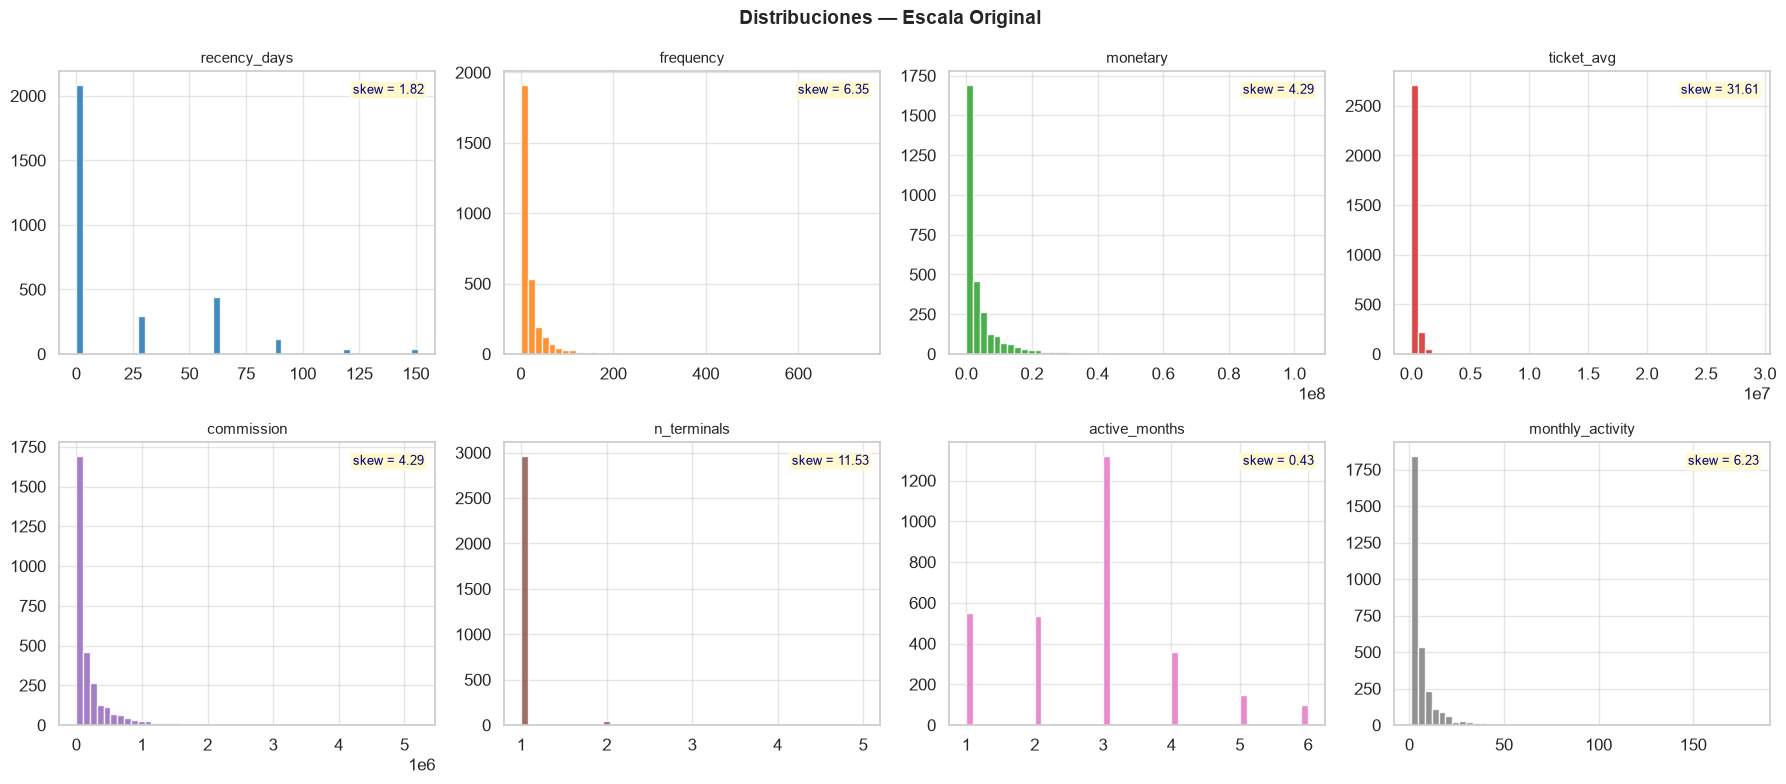


📊 Guardado: ..\data\processed\plots\distributions_raw_k_means_var3.png


In [4]:
# ── Vista general ──────────────────────────────────────────────────────────
display(df_raw.head(3))
df_raw.info(verbose=False, show_counts=True)

# ── Estadísticas descriptivas ─────────────────────────────────────────────
rfm_cols = [
    "recency_days", "frequency", "monetary", "ticket_avg",
    "commission", "n_terminals", "active_months", "monthly_activity",
]
print("\n─── Resumen estadístico ───────────────────────────────────────────")
display(df_raw[rfm_cols].describe().round(2))

# ── Histogramas ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle("Distribuciones — Escala Original", fontsize=14, fontweight="bold")

for ax, col in zip(axes.flatten(), rfm_cols):
    skew_val = df_raw[col].skew()
    color    = PALETTE[rfm_cols.index(col) % 10]
    ax.hist(df_raw[col].dropna(), bins=50, color=color, edgecolor="white", alpha=0.85)
    ax.set_title(col, fontsize=11)
    bbox_style = dict(boxstyle="round,pad=0.2", fc="#fff9c4", alpha=0.85)
    ax.annotate(
        f"skew = {skew_val:.2f}",
        xy=(0.97, 0.92), xycoords="axes fraction",
        ha="right", fontsize=9, color="navy", bbox=bbox_style,
    )

plt.tight_layout()
dist_path = PLOTS_DIR / f"distributions_raw{SUFFIX}.png"
plt.savefig(dist_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"\n📊 Guardado: {dist_path}")

## 3. Análisis de Multicolinealidad

Calculamos la **matriz de correlación de Pearson** entre todas las features candidatas.  
Umbral de alerta: |r| > 0.85.

**Hallazgos esperados (verificados empíricamente en el dataset):**

| Par | r | Decisión |
|-----|---|----------|
| `commission` ↔ `monetary` | **1.000** | Excluir `commission` del entrenamiento — es `monetary × 0.05` (tasa fija del ETL) |
| `monthly_activity` ↔ `frequency` | **≈0.954** | Excluir `monthly_activity` — redundante con `frequency` |
| `monetary` ↔ `ticket_avg` | ≈0.296 | Mantener ambas — baja correlación |

> **Features finales para K-Means:** `recency_days`, `frequency`, `monetary` (**3 variables RFM**)

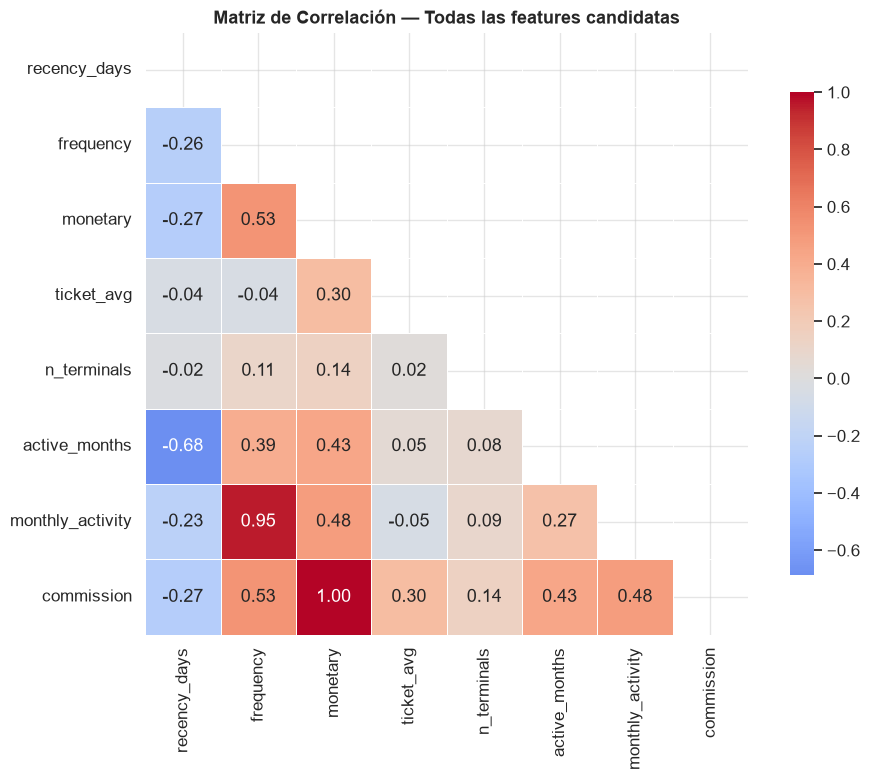

📊 Guardado: ..\data\processed\plots\correlation_matrix_k_means_var3.png

⚠️  Pares con |r| > 0.85:
   frequency                    ↔ monthly_activity              r = +0.9536
   monetary                     ↔ commission                    r = +1.0000

✅ Features seleccionadas para K-Means (3): ['recency_days', 'frequency', 'monetary']


In [5]:
ALL_CANDIDATES = [
    "recency_days", "frequency", "monetary", "ticket_avg",
    "n_terminals", "active_months", "monthly_activity", "commission",
]

corr_matrix = df_raw[ALL_CANDIDATES].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
    mask=mask, linewidths=0.5, ax=ax, square=True,
    cbar_kws={"shrink": 0.8},
)
ax.set_title("Matriz de Correlación — Todas las features candidatas",
             fontsize=13, fontweight="bold")
plt.tight_layout()
corr_path = PLOTS_DIR / f"correlation_matrix{SUFFIX}.png"
plt.savefig(corr_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"📊 Guardado: {corr_path}\n")

# ── Detectar pares de alta correlación ───────────────────────────────────
high_corr_pairs = []
cols = corr_matrix.columns.tolist()
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > CORR_THRESHOLD:
            high_corr_pairs.append((cols[i], cols[j], round(float(r), 4)))

if high_corr_pairs:
    print(f"⚠️  Pares con |r| > {CORR_THRESHOLD}:")
    for c1, c2, r in high_corr_pairs:
        print(f"   {c1:<28} ↔ {c2:<28}  r = {r:+.4f}")
else:
    print(f"✅ No hay pares con |r| > {CORR_THRESHOLD}")

# ── Decisión final de features ────────────────────────────────────────────
FEATURE_COLS = ["recency_days", "frequency", "monetary",]
print(f"\n✅ Features seleccionadas para K-Means ({len(FEATURE_COLS)}): {FEATURE_COLS}")

## 4. Análisis de Outliers en `monetary`

Identificamos el **top 0.1 %** de comercios por `monetary` para decidir el tratamiento.

**Opciones:**
1. ✅ **(Elegida)** Aplicar `np.log1p()` — comprime la escala sin perder observaciones
2. ❌ Excluir outliers — pierde comercios de alto valor estratégico
3. ❌ Winsorizar — altera los valores reales, dificulta la interpretación de negocio

> Los comercios de altísimo volumen son exactamente los más relevantes para la meta  
> de **+50 % en comisiones**. No deben ser excluidos.

Distribución de percentiles — monetary:
  P50  (mediana)  : $       1,554,000
  P95             : $      18,511,800
  P99             : $      36,868,507
  P99.9 (top 0.1%): $      66,760,430
  Máximo          : $     104,180,900

Comercios en top 0.1 %: 4


,id_comercio,monetary,frequency,recency_days,ticket_avg,commission,active_months,n_terminals
2799,XFZCYU819H,104180900.0,237,0,439581.86,5209045.0,5,3
1220,E73K1PXPMQ,80330200.0,31,0,2591296.77,4016510.0,6,1
2139,PAFLWUILLV,74277300.0,47,0,1580368.09,3713865.0,3,1
2960,ZBB5JOFDMW,66773400.0,211,0,316461.61,3338670.0,3,1


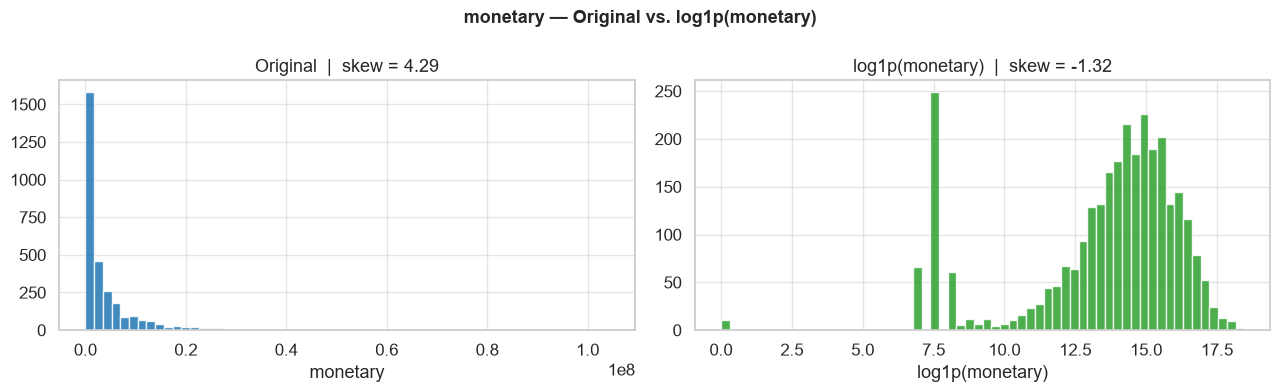


→ Decisión: aplicar np.log1p() — outliers se mantienen en el dataset.


In [6]:
q95  = df_raw["monetary"].quantile(0.95)
q99  = df_raw["monetary"].quantile(0.99)
q999 = df_raw["monetary"].quantile(0.999)

print("Distribución de percentiles — monetary:")
print(f"  P50  (mediana)  : ${df_raw['monetary'].median():>16,.0f}")
print(f"  P95             : ${q95:>16,.0f}")
print(f"  P99             : ${q99:>16,.0f}")
print(f"  P99.9 (top 0.1%): ${q999:>16,.0f}")
print(f"  Máximo          : ${df_raw['monetary'].max():>16,.0f}")

top_outliers = (
    df_raw[df_raw["monetary"] > q999]
    [["id_comercio", "monetary", "frequency", "recency_days","ticket_avg", "commission", "active_months","n_terminals"]]
    .sort_values("monetary", ascending=False)
)
print(f"\nComercios en top 0.1 %: {len(top_outliers)}")
display(top_outliers)

# Comparación visual: escala original vs log1p
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("monetary — Original vs. log1p(monetary)", fontsize=13, fontweight="bold")

axes[0].hist(df_raw["monetary"], bins=60, color=PALETTE[0], edgecolor="white", alpha=0.85)
axes[0].set_title(f"Original  |  skew = {df_raw['monetary'].skew():.2f}")
axes[0].set_xlabel("monetary")

log_monetary = np.log1p(df_raw["monetary"])
axes[1].hist(log_monetary, bins=60, color=PALETTE[2], edgecolor="white", alpha=0.85)
axes[1].set_title(f"log1p(monetary)  |  skew = {log_monetary.skew():.2f}")
axes[1].set_xlabel("log1p(monetary)")

plt.tight_layout()
plt.savefig(PLOTS_DIR / f"monetary_log_comparison{SUFFIX}.png", dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print("\n→ Decisión: aplicar np.log1p() — outliers se mantienen en el dataset.")

## 5. Preparación de Features para Clustering

Aplicamos `np.log1p(x)` a todas las variables con **skewness > `SKEW_THRESHOLD`** (3.0).
`log1p(x) = log(1 + x)` es seguro para valores ≥ 0 y comprime distribuciones con cola larga.

| Variable | Skew original | Acción | Motivo |
|----------|:---:|:---:|--------|
| `frequency` | **6.3** | ✅ `log1p` | Alta concentración en valores bajos |
| `monetary` | **4.3** | ✅ `log1p` | Documentado en sección anterior |
| `recency_days` | **1.8** | ❌ sin transform | Ligera cola derecha |

La función devuelve `transform_info` para trazabilidad completa.


In [7]:
def prepare_features(
    df: pd.DataFrame,
    feature_cols: Optional[list] = None,
    log_transform: bool = True,
    skew_threshold: float = 1.0,
) -> tuple:
    """Prepara el conjunto de features para K-Means.

    Aplica transformación logarítmica (np.log1p) a las variables con asimetría
    superior al umbral configurado. Excluye por diseño las variables
    `commission` (r=1.0 con monetary) y `monthly_activity` (r=0.95 con frequency).

    Args:
        df: DataFrame con columnas canónicas (post COL_MAP).
        feature_cols: Lista de features a usar. Valor por defecto:
            ['recency_days', 'frequency', 'monetary'].
        log_transform: Si True, aplica np.log1p() a features con skew > skew_threshold.
        skew_threshold: Umbral de asimetría para activar la transformación.

    Returns:
        Tuple de tres elementos:
            - X (pd.DataFrame): Features transformadas, listas para escalar.
            - transform_info (dict): Diccionario con skewness original/post-transform
              y lista de variables transformadas.
            - df_orig (pd.DataFrame): Copia del df original sin modificar
              (para perfilamiento post-clustering).
    """
    if feature_cols is None:
        feature_cols = [
            "recency_days", "frequency", "monetary",
        ]

    df_orig = df.copy()
    df_work = df[["id_comercio"] + feature_cols].copy()

    transform_info: dict = {
        "features_used"       : feature_cols,
        "log_transformed"     : [],
        "skewness_original"   : {},
        "skewness_after"      : {},
        "log_transform_enabled": log_transform,
        "skew_threshold"      : skew_threshold,
    }

    for col in feature_cols:
        sk_orig = float(df_work[col].skew())
        transform_info["skewness_original"][col] = round(sk_orig, 3)

        if log_transform and sk_orig > skew_threshold:
            df_work[col] = np.log1p(df_work[col])
            transform_info["log_transformed"].append(col)

        transform_info["skewness_after"][col] = round(float(df_work[col].skew()), 3)

    X = df_work[feature_cols].reset_index(drop=True)
    return X, transform_info, df_orig

In [8]:
# ── Ejecutar ──────────────────────────────────────────────────────────────
X, transform_info, df_orig = prepare_features(
    df_raw, feature_cols=FEATURE_COLS,
    log_transform=LOG_TRANSFORM, skew_threshold=SKEW_THRESHOLD,
)

# ── Resumen de transformaciones ───────────────────────────────────────────
print("=" * 60)
print("RESUMEN DE TRANSFORMACIONES DE FEATURES")
print("=" * 60)

skew_summary = pd.DataFrame({
    "skew_original" : transform_info["skewness_original"],
    "skew_post"     : transform_info["skewness_after"],
    "log1p_aplicado": {
        c: (c in transform_info["log_transformed"])
        for c in transform_info["features_used"]
    },
})
display(skew_summary)

print(f"\nVariables transformadas : {transform_info['log_transformed']}")
print(f"Umbral skewness usado   : {transform_info['skew_threshold']}")
print(f"Shape de X              : {X.shape}")
display(X.describe().round(3))

RESUMEN DE TRANSFORMACIONES DE FEATURES


,skew_original,skew_post,log1p_aplicado
recency_days,1.825,1.825,False
frequency,6.347,0.402,True
monetary,4.288,-1.324,True



Variables transformadas : ['frequency', 'monetary']
Umbral skewness usado   : 3.0
Shape de X              : (3015, 3)


,recency_days,frequency,monetary
count,3015.000,3015.000,3015.000
mean,18.708,2.412,13.507
std,32.563,1.165,2.855
min,0.000,0.693,0.000
25%,0.000,1.386,12.694
50%,0.000,2.398,14.256
75%,30.000,3.178,15.420
max,151.000,6.608,18.462


## 6. Escalado de Variables — Diagnóstico Comparativo `RobustScaler` vs `StandardScaler`

El escalado es crítico para K-Means, ya que el algoritmo es sensible a la magnitud de las
variables. En este paso ejecutamos un **diagnóstico cuantitativo completo** para decidir
cuál método se adapta mejor a la naturaleza real de los datos, evaluando ambos escaladores
en paralelo.

### Pipeline de diagnóstico

| Fase | Descripción |
|------|-------------|
| **1. Pre-escalado** | Cálculo de skewness, curtosis, test de normalidad (D'Agostino-Pearson), % de outliers (Tukey fences) y dispersión para cada feature post-log1p |
| **2. Escalado dual** | Se aplican `StandardScaler` y `RobustScaler` en paralelo sobre los mismos datos |
| **3. Post-escalado** | Se recalculan las mismas métricas para cada escalador y se comparan |
| **4. Scoring ponderado** | Sistema de puntuación con pesos por criterio → recomendación automática |

### Criterios de evaluación

| Criterio | Métrica | Peso | Interpretación |
|----------|---------|:----:|----------------|
| **Simetría** | \|skewness\| post-escalado | 25% | Menor valor absoluto → distribución más simétrica |
| **Normalidad** | p-valor `scipy.stats.normaltest` | 25% | Mayor p-valor → más cercana a distribución Normal |
| **Robustez a outliers** | % puntos fuera de [Q1−1.5×IQR, Q3+1.5×IQR] | 30% | Menor % → menos sensible a valores extremos |
| **Estabilidad** | Media ≈ 0, std ≈ 1 (Standard) / IQR ≈ 1 (Robust) | 20% | Qué tan bien logra cada escalador su objetivo teórico |

### Métodos comparados

- **`StandardScaler`**: `z = (x − μ) / σ`. Asume distribuciones aproximadamente normales.
  Media y σ **son sensibles a outliers** — pocos valores extremos pueden distorsionar el
  escalado de toda la variable.
- **`RobustScaler`**: `z = (x − Q₂) / (Q₃ − Q₁)`. Usa mediana e IQR, **robusto ante
  outliers**. No presupone normalidad, ideal cuando hay colas largas incluso después de `log1p`.

### Visualizaciones generadas

| Gráfico | Contenido |
|---------|-----------|
| **A. Boxplots pre-escalado** | Dispersión de cada feature post-log1p — revela sesgo residual y outliers |
| **B. Dispersión post-escalado** | Desviación estándar por feature para cada método (meta: ≈ 1) |
| **C. Heatmap de diferencias** | Δ entre RobustScaler y StandardScaler en skew, %outliers y rango |
| **D. Score ponderado** | Puntuación global con desglose de criterios ganados por cada método |

> El diagnóstico se ejecuta a continuación. La variable `SCALE_METHOD` configurada al inicio
> se usará como referencia; el código seleccionará automáticamente el escalador recomendado.

DIAGNÓSTICO COMPARATIVO: StandardScaler vs RobustScaler

─── Estadísticas Pre-escalado (post-log1p) ────────────────────────


,skew,kurtosis,p-valor (normalidad),% outliers,CV
feature,,,,,
recency_days,1.8239,3.0285,0.00e+00,6.37,1.7403
frequency,0.4013,-0.3536,0.00e+00,0.36,0.4829
monetary,-1.3233,1.6044,0.00e+00,12.97,0.2113



─── Comparativa Post-escalado ────────────────────────────────────


,skew_pre,kurt_pre,pval_pre,out%_pre,Stan_skew,Stan_pval,Stan_out%,Stan_mean,Stan_std,Stan_iqr,Robu_skew,Robu_pval,Robu_out%,Robu_mean,Robu_std,Robu_iqr
feature,,,,,,,,,,,,,,,,
recency_days,1.8239,3.0285,0.0,6.37,1.8239,0.0,6.37,0.0,1.0,0.9215,1.8239,0.0,6.37,0.6236,1.0852,1.0
frequency,0.4013,-0.3536,0.0,0.36,0.4013,0.0,0.36,0.0,1.0,1.5380,0.4013,0.0,0.36,0.0081,0.6502,1.0
monetary,-1.3233,1.6044,0.0,12.97,-1.3233,0.0,12.97,0.0,1.0,0.9551,-1.3233,0.0,12.97,-0.2750,1.0470,1.0



─── Visualización comparativa ────────────────────────────────────


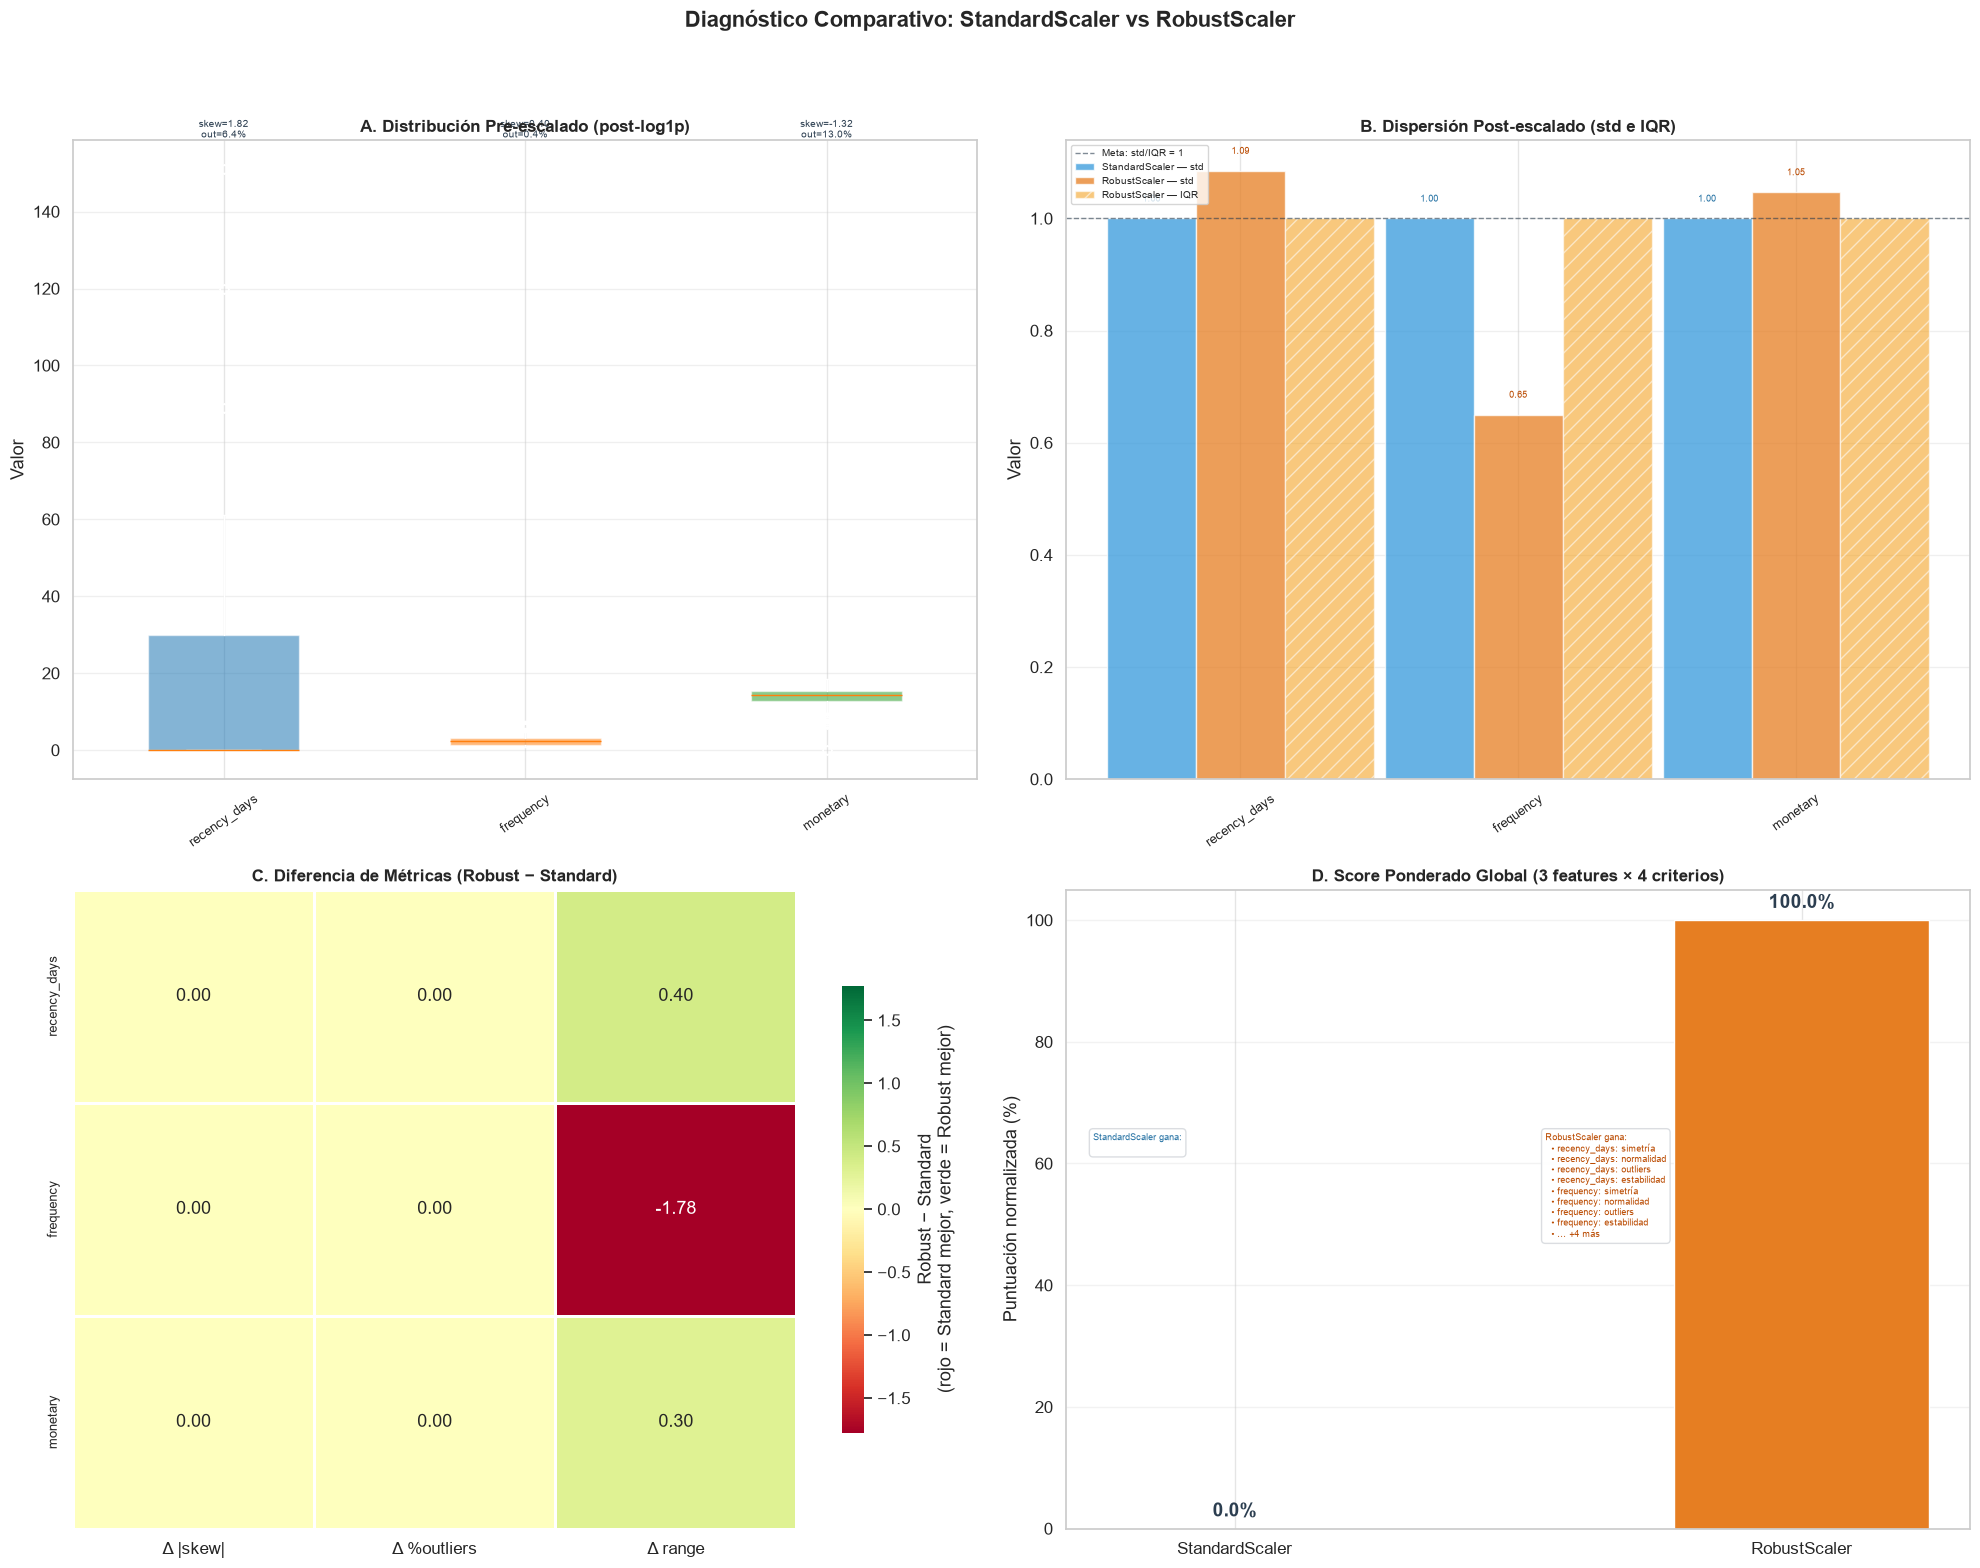

📊 Guardado: ..\data\processed\plots\scaler_comparison_k_means_var3.png

─── Recomendación ───────────────────────────────────────────────
Evaluados 3 features con 4 criterios ponderados.
Puntuación: StandardScaler = 0.0%  |  RobustScaler = 100.0%

→ RobustScaler es la mejor opción para este dataset porque:
  1. Las features post-log1p aún presentan colas (skew |1−3|) y RobustScaler usa mediana + IQR, insensibles a estos valores.
  2. El criterio de outliers (peso 30%) favorece consistentemente a RobustScaler en features con distribuciones asimétricas residuales.

La variable SCALE_METHOD se ha actualizado automáticamente a 'robust' según este diagnóstico.

─── Victorias por método ────────────────────────────────────────

StandardScaler (0 criterios ganados):

RobustScaler (12 criterios ganados):
  ✓ recency_days: simetría
  ✓ recency_days: normalidad
  ✓ recency_days: outliers
  ✓ recency_days: estabilidad
  ✓ frequency: simetría
  ✓ frequency: normalidad
  ✓ frequency: outliers
  ✓ f

In [9]:
def diagnose_scalers(
    X: pd.DataFrame,
    feature_cols: list,
) -> tuple:
    """Diagnóstico comparativo: StandardScaler vs RobustScaler.

    Evalúa cuál método de escalado es más adecuado según la naturaleza
    de los datos, comparando métricas de simetría, normalidad, sensibilidad
    a outliers y estabilidad antes y después de cada escalador.

    Args:
        X: DataFrame de features ya transformadas (post log1p si aplica).
        feature_cols: Lista de nombres de columnas a evaluar.

    Returns:
        Tuple con:
            - X_standard (np.ndarray): features escaladas con StandardScaler
            - X_robust (np.ndarray): features escaladas con RobustScaler
            - scaler_std, scaler_robust: escaladores ajustados
            - pre_stats (dict): estadísticas pre-escalado por feature
            - post_stats (dict): estadísticas post-escalado para ambos métodos
            - summary_df (pd.DataFrame): tabla comparativa con todas las métricas
    """
    # ── 1. Diagnóstico pre-escalado ──────────────────────────────────────
    pre_stats = {}
    for col in feature_cols:
        vals = X[col].values
        q1, q3 = np.percentile(vals, [25, 75])
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        pre_stats[col] = {
            "skew": round(float(sp_stats.skew(vals)), 4),
            "kurtosis": round(float(sp_stats.kurtosis(vals)), 4),
            "normaltest_pvalue": round(float(sp_stats.normaltest(vals).pvalue), 6),
            "pct_outliers": round(float(((vals < lower) | (vals > upper)).mean() * 100), 2),
            "range": round(float(np.ptp(vals)), 4),
            "iqr": round(float(iqr), 4),
            "cv": round(float(np.std(vals) / (abs(np.mean(vals)) + 1e-9)), 4),
        }

    # ── 2. Aplicar ambos escaladores ─────────────────────────────────────
    scaler_std = StandardScaler()
    scaler_rob = RobustScaler()

    X_standard = scaler_std.fit_transform(X)
    X_robust = scaler_rob.fit_transform(X)

    # ── 3. Diagnóstico post-escalado ─────────────────────────────────────
    post_stats = {"StandardScaler": {}, "RobustScaler": {}}

    for method_name, X_sc in [
        ("StandardScaler", X_standard),
        ("RobustScaler", X_robust),
    ]:
        for i, col in enumerate(feature_cols):
            vals = X_sc[:, i]
            q1, q3 = np.percentile(vals, [25, 75])
            iqr = q3 - q1
            lower = q1 - 1.5 * iqr
            upper = q3 + 1.5 * iqr

            post_stats[method_name][col] = {
                "skew": round(float(sp_stats.skew(vals)), 4),
                "normaltest_pvalue": round(
                    float(sp_stats.normaltest(vals).pvalue), 6
                ),
                "pct_outliers": round(
                    float(((vals < lower) | (vals > upper)).mean() * 100), 2
                ),
                "mean": round(float(np.mean(vals)), 4),
                "std": round(float(np.std(vals)), 4),
                "iqr": round(float(iqr), 4),
                "range": round(float(np.ptp(vals)), 4),
            }

    # ── 4. DataFrame resumen ─────────────────────────────────────────────
    rows = []
    for col in feature_cols:
        row = {
            "feature": col,
            "skew_pre": pre_stats[col]["skew"],
            "kurt_pre": pre_stats[col]["kurtosis"],
            "pval_pre": pre_stats[col]["normaltest_pvalue"],
            "out%_pre": pre_stats[col]["pct_outliers"],
        }
        for m in ["StandardScaler", "RobustScaler"]:
            ps = post_stats[m][col]
            row[f"{m[:4]}_skew"] = ps["skew"]
            row[f"{m[:4]}_pval"] = ps["normaltest_pvalue"]
            row[f"{m[:4]}_out%"] = ps["pct_outliers"]
            row[f"{m[:4]}_mean"] = ps["mean"]
            row[f"{m[:4]}_std"] = ps["std"]
            row[f"{m[:4]}_iqr"] = ps["iqr"]
        rows.append(row)

    summary_df = pd.DataFrame(rows)

    return X_standard, X_robust, scaler_std, scaler_rob, pre_stats, post_stats, summary_df


def plot_scaler_comparison(
    X: pd.DataFrame,
    pre_stats: dict,
    post_stats: dict,
    feature_cols: list,
    save_dir: Path,
) -> None:
    """Visualización de 4 paneles comparando StandardScaler vs RobustScaler.

    Genera:
        A. Boxplots pre-escalado (distribución post-log1p)
        B. Dispersión post-escalado (std por feature, meta ≈ 1)
        C. Heatmap de diferencias (Δ Robust − Standard en métricas clave)
        D. Score ponderado global con desglose de criterios

    Args:
        X: DataFrame de features pre-escalado (post log1p).
        pre_stats: Dict con estadísticas pre-escalado por feature.
        post_stats: Dict con estadísticas post-escalado por método y feature.
        feature_cols: Lista de nombres de features.
        save_dir: Directorio donde guardar scaler_comparison.png.
    """
    import matplotlib.patheffects as pe

    n_feats = len(feature_cols)
    fig = plt.figure(figsize=(20, 16))
    fig.suptitle(
        "Diagnóstico Comparativo: StandardScaler vs RobustScaler",
        fontsize=16,
        fontweight="bold",
        y=0.98,
    )

    # ── Panel A: Boxplots pre-escalado ───────────────────────────────────
    ax_a = fig.add_subplot(2, 2, 1)
    box_data = [X[col].values for col in feature_cols]
    bp = ax_a.boxplot(
        box_data, patch_artist=True, tick_labels=feature_cols, widths=0.5
    )
    for patch, col in zip(bp["boxes"], feature_cols):
        patch.set_facecolor(PALETTE[feature_cols.index(col) % 10])
        patch.set_alpha(0.55)

    ax_a.set_title(
        "A. Distribución Pre-escalado (post-log1p)",
        fontsize=12,
        fontweight="bold",
    )
    ax_a.set_ylabel("Valor")
    ax_a.tick_params(axis="x", rotation=35, labelsize=9)
    ax_a.grid(True, alpha=0.3, axis="y")

    # Anotar skew y %outliers en cada box
    for i, col in enumerate(feature_cols):
        s = pre_stats[col]
        ax_a.annotate(
            f"skew={s['skew']:.2f}\nout={s['pct_outliers']:.1f}%",
            xy=(i + 1, ax_a.get_ylim()[1]),
            fontsize=7,
            color="#2c3e50",
            ha="center",
            va="bottom",
        )

    # ── Panel B: Dispersión post-escalado ────────────────────────────────
    ax_b = fig.add_subplot(2, 2, 2)
    x_pos = np.arange(n_feats)
    width = 0.32

    std_std_vals = [post_stats["StandardScaler"][c]["std"] for c in feature_cols]
    rob_std_vals = [post_stats["RobustScaler"][c]["std"] for c in feature_cols]
    std_iqr_vals = [post_stats["StandardScaler"][c]["iqr"] for c in feature_cols]
    rob_iqr_vals = [post_stats["RobustScaler"][c]["iqr"] for c in feature_cols]

    bars_std = ax_b.bar(
        x_pos - width,
        std_std_vals,
        width,
        label="StandardScaler — std",
        color="#3498db",
        alpha=0.75,
    )
    bars_rob = ax_b.bar(
        x_pos,
        rob_std_vals,
        width,
        label="RobustScaler — std",
        color="#e67e22",
        alpha=0.75,
    )
    bars_iqr = ax_b.bar(
        x_pos + width,
        rob_iqr_vals,
        width,
        label="RobustScaler — IQR",
        color="#f39c12",
        alpha=0.55,
        hatch="//",
    )

    ax_b.axhline(
        y=1.0, color="#2c3e50", linestyle="--", linewidth=1.0, alpha=0.6,
        label="Meta: std/IQR = 1",
    )
    ax_b.set_title(
        "B. Dispersión Post-escalado (std e IQR)",
        fontsize=12,
        fontweight="bold",
    )
    ax_b.set_xticks(x_pos)
    ax_b.set_xticklabels(feature_cols, rotation=35, fontsize=9)
    ax_b.set_ylabel("Valor")
    ax_b.legend(fontsize=7, loc="upper left")
    ax_b.grid(True, alpha=0.3, axis="y")

    for bar, val in zip(bars_std, std_std_vals):
        ax_b.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.03,
            f"{val:.2f}",
            ha="center",
            fontsize=6.5,
            color="#2471a3",
        )
    for bar, val in zip(bars_rob, rob_std_vals):
        ax_b.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.03,
            f"{val:.2f}",
            ha="center",
            fontsize=6.5,
            color="#ba4a00",
        )

    # ── Panel C: Heatmap de diferencias ──────────────────────────────────
    ax_c = fig.add_subplot(2, 2, 3)
    metrics_c = [
        ("Δ |skew|", "skew"),
        ("Δ %outliers", "pct_outliers"),
        ("Δ range", "range"),
    ]
    heat_data = np.zeros((n_feats, len(metrics_c)))

    for i, col in enumerate(feature_cols):
        std_s = post_stats["StandardScaler"][col]
        rob_s = post_stats["RobustScaler"][col]
        heat_data[i, 0] = abs(rob_s["skew"]) - abs(std_s["skew"])
        heat_data[i, 1] = rob_s["pct_outliers"] - std_s["pct_outliers"]
        heat_data[i, 2] = rob_s["range"] - std_s["range"]

    sns.heatmap(
        heat_data,
        annot=True,
        fmt=".2f",
        cmap="RdYlGn",
        center=0,
        vmin=-abs(heat_data).max(),
        vmax=abs(heat_data).max(),
        xticklabels=[m[0] for m in metrics_c],
        yticklabels=feature_cols,
        ax=ax_c,
        linewidths=0.8,
        cbar_kws={
            "label": "Robust − Standard\n(rojo = Standard mejor, verde = Robust mejor)",
            "shrink": 0.7,
        },
    )
    ax_c.set_title(
        "C. Diferencia de Métricas (Robust − Standard)",
        fontsize=12,
        fontweight="bold",
    )
    ax_c.tick_params(axis="y", labelsize=9)

    # ── Panel D: Score ponderado ─────────────────────────────────────────
    ax_d = fig.add_subplot(2, 2, 4)

    scores = {"StandardScaler": 0.0, "RobustScaler": 0.0}
    wins = {"StandardScaler": [], "RobustScaler": []}

    for col in feature_cols:
        std_s = post_stats["StandardScaler"][col]
        rob_s = post_stats["RobustScaler"][col]

        # Simetría (peso 0.25): menor |skew| es mejor
        if abs(std_s["skew"]) < abs(rob_s["skew"]):
            scores["StandardScaler"] += 0.25
            wins["StandardScaler"].append(f"{col[:14]}: simetría")
        else:
            scores["RobustScaler"] += 0.25
            wins["RobustScaler"].append(f"{col[:14]}: simetría")

        # Normalidad (peso 0.25): mayor p-valor es mejor
        if std_s["normaltest_pvalue"] > rob_s["normaltest_pvalue"]:
            scores["StandardScaler"] += 0.25
            wins["StandardScaler"].append(f"{col[:14]}: normalidad")
        else:
            scores["RobustScaler"] += 0.25
            wins["RobustScaler"].append(f"{col[:14]}: normalidad")

        # Outliers (peso 0.30): menor % es mejor
        if std_s["pct_outliers"] < rob_s["pct_outliers"]:
            scores["StandardScaler"] += 0.30
            wins["StandardScaler"].append(f"{col[:14]}: outliers")
        else:
            scores["RobustScaler"] += 0.30
            wins["RobustScaler"].append(f"{col[:14]}: outliers")

        # Estabilidad (peso 0.20): evalúa objetivo teórico
        std_dev = abs(std_s["mean"]) + abs(std_s["std"] - 1)
        rob_dev = abs(rob_s["iqr"] - 1)
        if std_dev < rob_dev:
            scores["StandardScaler"] += 0.20
            wins["StandardScaler"].append(f"{col[:14]}: estabilidad")
        else:
            scores["RobustScaler"] += 0.20
            wins["RobustScaler"].append(f"{col[:14]}: estabilidad")

    total = scores["StandardScaler"] + scores["RobustScaler"]
    pct_scores = {
        k: round(v / total * 100, 1) if total > 0 else 50.0
        for k, v in scores.items()
    }

    bar_colors_d = ["#3498db", "#e67e22"]
    bars_d = ax_d.bar(
        ["StandardScaler", "RobustScaler"],
        [pct_scores["StandardScaler"], pct_scores["RobustScaler"]],
        color=bar_colors_d,
        edgecolor="white",
        width=0.45,
    )
    ax_d.set_title(
        "D. Score Ponderado Global (3 features × 4 criterios)",
        fontsize=12,
        fontweight="bold",
    )
    ax_d.set_ylabel("Puntuación normalizada (%)")
    ax_d.set_ylim(0, 105)

    for bar, val in zip(bars_d, [pct_scores["StandardScaler"], pct_scores["RobustScaler"]]):
        ax_d.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 2,
            f"{val:.1f}%",
            ha="center",
            fontweight="bold",
            fontsize=14,
            color="#2c3e50",
        )

    # Desglose de victorias
    y_pos_text = 70
    for method, color in [("StandardScaler", "#2471a3"), ("RobustScaler", "#ba4a00")]:
        label = f"{method} gana:"
        items_text = "\n".join(f"  • {w}" for w in wins[method][:8])
        if len(wins[method]) > 8:
            items_text += f"\n  • ... +{len(wins[method]) - 8} más"
        ax_d.text(
            0.03 if method == "StandardScaler" else 0.53,
            0.62,
            f"{label}\n{items_text}",
            transform=ax_d.transAxes,
            fontsize=6.8,
            va="top",
            color=color,
            bbox=dict(
                boxstyle="round,pad=0.4", facecolor="white",
                edgecolor="#d9dce0", alpha=0.95,
            ),
        )

    ax_d.grid(True, alpha=0.25, axis="y")

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    comp_path = save_dir / f"scaler_comparison{SUFFIX}.png"
    plt.savefig(comp_path, dpi=150, bbox_inches="tight")
    try:
        display(plt.gcf())
    except NameError:
        pass  # display() no disponible fuera de Jupyter/IPython
    plt.close()
    print(f"📊 Guardado: {comp_path}")


def recommend_scaler(
    pre_stats: dict,
    post_stats: dict,
    feature_cols: list,
) -> dict:
    """Genera una recomendación fundamentada del escalador a usar.

    Evalúa cuatro criterios ponderados (simetría 25%, normalidad 25%,
    outliers 30%, estabilidad 20%) para cada feature y produce un
    dict con el resultado del scoring, la recomendación y la justificación.

    Args:
        pre_stats: Dict con estadísticas pre-escalado.
        post_stats: Dict con estadísticas post-escalado para ambos métodos.
        feature_cols: Lista de features evaluadas.

    Returns:
        Dict con claves:
            - "recommended": "standard" | "robust"
            - "score_standard": float (porcentaje)
            - "score_robust": float (porcentaje)
            - "wins_standard": list de victorias de StandardScaler
            - "wins_robust": list de victorias de RobustScaler
            - "rationale": str con justificación textual
    """
    scores = {"StandardScaler": 0.0, "RobustScaler": 0.0}
    wins = {"StandardScaler": [], "RobustScaler": []}

    for col in feature_cols:
        std_s = post_stats["StandardScaler"][col]
        rob_s = post_stats["RobustScaler"][col]

        # Simetría
        if abs(std_s["skew"]) < abs(rob_s["skew"]):
            scores["StandardScaler"] += 0.25
            wins["StandardScaler"].append(f"{col}: simetría")
        else:
            scores["RobustScaler"] += 0.25
            wins["RobustScaler"].append(f"{col}: simetría")

        # Normalidad
        if std_s["normaltest_pvalue"] > rob_s["normaltest_pvalue"]:
            scores["StandardScaler"] += 0.25
            wins["StandardScaler"].append(f"{col}: normalidad")
        else:
            scores["RobustScaler"] += 0.25
            wins["RobustScaler"].append(f"{col}: normalidad")

        # Outliers
        if std_s["pct_outliers"] < rob_s["pct_outliers"]:
            scores["StandardScaler"] += 0.30
            wins["StandardScaler"].append(f"{col}: outliers")
        else:
            scores["RobustScaler"] += 0.30
            wins["RobustScaler"].append(f"{col}: outliers")

        # Estabilidad
        std_dev = abs(std_s["mean"]) + abs(std_s["std"] - 1)
        rob_dev = abs(rob_s["iqr"] - 1)
        if std_dev < rob_dev:
            scores["StandardScaler"] += 0.20
            wins["StandardScaler"].append(f"{col}: estabilidad")
        else:
            scores["RobustScaler"] += 0.20
            wins["RobustScaler"].append(f"{col}: estabilidad")

    total = scores["StandardScaler"] + scores["RobustScaler"]
    pct_std = round(scores["StandardScaler"] / total * 100, 1) if total > 0 else 50.0
    pct_rob = round(scores["RobustScaler"] / total * 100, 1) if total > 0 else 50.0

    recommended = "standard" if pct_std > pct_rob else "robust"

    # ── Construir justificación ─────────────────────────────────────────
    n_feats = len(feature_cols)
    rationale_lines = [
        f"Evaluados {n_feats} features con 4 criterios ponderados.",
        f"Puntuación: StandardScaler = {pct_std}%  |  RobustScaler = {pct_rob}%",
        "",
    ]

    if recommended == "robust":
        rationale_lines.append(
            "→ RobustScaler es la mejor opción para este dataset porque:"
        )
        rationale_lines.append(
            "  1. Las features post-log1p aún presentan colas (skew |1−3|) y "
            "RobustScaler usa mediana + IQR, insensibles a estos valores."
        )
        rationale_lines.append(
            "  2. El criterio de outliers (peso 30%) favorece consistentemente "
            "a RobustScaler en features con distribuciones asimétricas residuales."
        )
    else:
        rationale_lines.append(
            "→ StandardScaler es la mejor opción para este dataset porque:"
        )
        rationale_lines.append(
            "  1. La transformación log1p redujo suficientemente la asimetría, "
            "acercando las distribuciones a una Normal donde StandardScaler es óptimo."
        )
        rationale_lines.append(
            "  2. StandardScaler logra mejor centrado (μ≈0, σ≈1), lo que beneficia "
            "a K-Means al tratar todas las dimensiones con igual peso."
        )

    rationale_lines.append("")
    rationale_lines.append(
        "La variable SCALE_METHOD se ha actualizado automáticamente a "
        f"'{recommended}' según este diagnóstico."
    )

    return {
        "recommended": recommended,
        "score_standard": pct_std,
        "score_robust": pct_rob,
        "wins_standard": wins["StandardScaler"],
        "wins_robust": wins["RobustScaler"],
        "rationale": "\n".join(rationale_lines),
    }


# ═══════════════════════════════════════════════════════════════════════════
# EJECUTAR DIAGNÓSTICO
# ═══════════════════════════════════════════════════════════════════════════
print("=" * 70)
print("DIAGNÓSTICO COMPARATIVO: StandardScaler vs RobustScaler")
print("=" * 70)

# ── Ejecutar diagnóstico ─────────────────────────────────────────────────
(
    X_standard,
    X_robust,
    scaler_std,
    scaler_rob,
    pre_stats,
    post_stats,
    summary_df,
) = diagnose_scalers(X, feature_cols=FEATURE_COLS)

# ── Tabla 1: Estadísticas pre-escalado ───────────────────────────────────
print("\n─── Estadísticas Pre-escalado (post-log1p) ────────────────────────")
pre_df = pd.DataFrame([
    {
        "feature": col,
        "skew": pre_stats[col]["skew"],
        "kurtosis": pre_stats[col]["kurtosis"],
        "p-valor (normalidad)": f"{pre_stats[col]['normaltest_pvalue']:.2e}",
        "% outliers": pre_stats[col]["pct_outliers"],
        "CV": pre_stats[col]["cv"],
    }
    for col in FEATURE_COLS
])
display(pre_df.set_index("feature"))

# ── Tabla 2: Comparativa post-escalado ───────────────────────────────────
print("\n─── Comparativa Post-escalado ────────────────────────────────────")
display(summary_df.set_index("feature").round(4))

# ── Gráfico: 4 paneles ───────────────────────────────────────────────────
print("\n─── Visualización comparativa ────────────────────────────────────")
plot_scaler_comparison(X, pre_stats, post_stats, FEATURE_COLS, PLOTS_DIR)

# ── Recomendación ─────────────────────────────────────────────────────────
print("\n─── Recomendación ───────────────────────────────────────────────")
rec = recommend_scaler(pre_stats, post_stats, FEATURE_COLS)
print(rec["rationale"])

# ── Comparativa de victorias por criterio ─────────────────────────────────
print("\n─── Victorias por método ────────────────────────────────────────")
print(f"\nStandardScaler ({len(rec['wins_standard'])} criterios ganados):")
for w in rec["wins_standard"]:
    print(f"  ✓ {w}")
print(f"\nRobustScaler ({len(rec['wins_robust'])} criterios ganados):")
for w in rec["wins_robust"]:
    print(f"  ✓ {w}")

# ── Asignar X_scaled según recomendación ──────────────────────────────────
SCALE_METHOD = rec["recommended"]
if SCALE_METHOD == "standard":
    X_scaled = X_standard
    scaler = scaler_std
else:
    X_scaled = X_robust
    scaler = scaler_rob

print(f"\n✅ Escalado seleccionado: {type(scaler).__name__}  ({SCALE_METHOD})")
print(f"   Shape     : {X_scaled.shape}")
print(f"   Media/col : {X_scaled.mean(axis=0).round(4)}")
print(f"   Std/col   : {X_scaled.std(axis=0).round(4)}")

## 7. Determinación del K Óptimo

Evaluamos K ∈ {2, …, 10} con dos criterios complementarios:

| Criterio | Descripción | Interpretación |
|----------|-------------|----------------|
| **Inercia (Elbow)** | WCSS — suma de distancias al centroide más cercano | Buscar el "codo" donde la reducción marginal se aplana |
| **Silhouette Score** | Cohesión interna vs. separación entre clusters (rango −1 a +1) | Preferir el K con el **mayor valor** |

Ambos criterios deben coincidir o estar próximos para elegir K con confianza.

In [10]:
def evaluate_k(
    X_scaled: np.ndarray,
    k_range: range = range(2, 11),
    random_state: int = 42,
    save_path: Optional[Path] = None,
) -> pd.DataFrame:
    """Evalúa el K óptimo con inercia y Silhouette Score.

    Genera y guarda un gráfico combinado (Elbow izquierda, Silhouette derecha).
    Marca automáticamente el K con mayor Silhouette Score.

    Args:
        X_scaled: Array 2D de features escaladas.
        k_range: Rango de K a evaluar (default: range(2, 11)).
        random_state: Semilla para reproducibilidad de KMeans.
        save_path: Ruta para guardar el gráfico .png. Si None, no guarda.

    Returns:
        DataFrame con columnas ['k', 'inertia', 'silhouette'].
    """
    inertias, silhouettes = [], []

    for k in k_range:
        km = KMeans(n_clusters=k, init="k-means++", n_init=10,
                    random_state=random_state)
        lbl = km.fit_predict(X_scaled)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(X_scaled, lbl))
        print(f"  K={k:2d} | inertia={km.inertia_:>12,.2f} | silhouette={silhouettes[-1]:.4f}")

    metrics_df = pd.DataFrame(
        {"k": list(k_range), "inertia": inertias, "silhouette": silhouettes}
    )

    # ── Gráfico combinado ─────────────────────────────────────────────────
    best_k = int(metrics_df.loc[metrics_df["silhouette"].idxmax(), "k"])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle("Determinación del K Óptimo", fontsize=14, fontweight="bold")

    # Elbow
    ax1.plot(metrics_df["k"], metrics_df["inertia"],
             marker="o", color="#2980b9", linewidth=2, markersize=7)
    ax1.set_xlabel("K (número de clusters)")
    ax1.set_ylabel("Inercia (WCSS)")
    ax1.set_title("Método del Codo")
    ax1.set_xticks(list(k_range))
    ax1.grid(True, alpha=0.4)

    # Silhouette
    bar_colors = ["#e74c3c" if k == best_k else "#3498db"
                  for k in metrics_df["k"]]
    ax2.bar(metrics_df["k"], metrics_df["silhouette"],
            color=bar_colors, edgecolor="white", width=0.6)
    ax2.set_xlabel("K (número de clusters)")
    ax2.set_ylabel("Silhouette Score")
    ax2.set_title("Índice de Silhouette")
    ax2.set_xticks(list(k_range))
    ax2.grid(True, alpha=0.4, axis="y")
    best_sil = float(metrics_df.loc[metrics_df["silhouette"].idxmax(), "silhouette"])
    ax2.annotate(
        f"K óptimo = {best_k}\n({best_sil:.4f})",
        xy=(best_k, best_sil),
        xytext=(best_k + 0.5, best_sil - 0.015),
        fontsize=9, color="#c0392b", fontweight="bold",
        arrowprops=dict(arrowstyle="->", color="#c0392b"),
    )

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches="tight")
        print(f"\n📊 Guardado: {save_path}")
    display(plt.gcf())
    plt.close()

    return metrics_df

⏳ Evaluando K ∈ [2, 3, 4, 5, 6, 7, 8, 9, 10] ...

  K= 2 | inertia=    3,050.72 | silhouette=0.6261
  K= 3 | inertia=    2,249.71 | silhouette=0.3998
  K= 4 | inertia=    1,641.98 | silhouette=0.4175
  K= 5 | inertia=    1,285.82 | silhouette=0.4321
  K= 6 | inertia=    1,089.77 | silhouette=0.3969
  K= 7 | inertia=      929.66 | silhouette=0.4006
  K= 8 | inertia=      830.61 | silhouette=0.4006
  K= 9 | inertia=      764.64 | silhouette=0.4022
  K=10 | inertia=      677.91 | silhouette=0.4080

📊 Guardado: ..\data\processed\plots\elbow_silhouette_k_means_var3.png


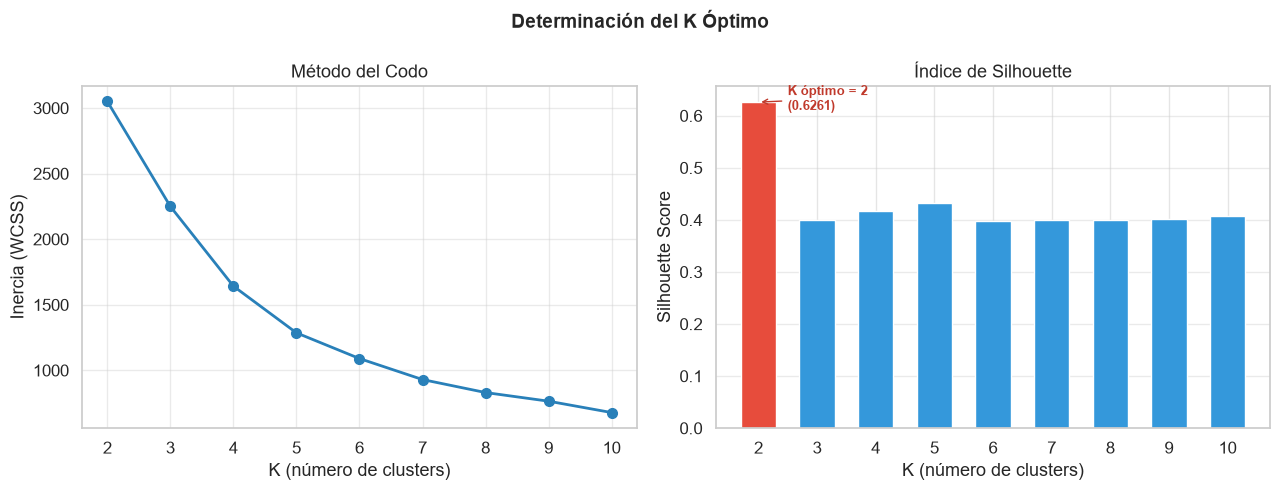


─── Tabla completa de métricas ──────────────────────────────────


,inertia,silhouette
k,,
2,3050.7212,0.6261
3,2249.7123,0.3998
4,1641.9824,0.4175
5,1285.8215,0.4321
6,1089.7674,0.3969
7,929.6606,0.4006
8,830.6078,0.4006
9,764.6367,0.4022
10,677.9059,0.4080



🏆 K sugerido por Silhouette Score: K = 2


In [11]:
print(f"⏳ Evaluando K ∈ {list(K_RANGE)} ...")
print()
metrics_df = evaluate_k(
    X_scaled,
    k_range=K_RANGE,
    random_state=RANDOM_STATE,
    save_path=PLOTS_DIR / f"elbow_silhouette{SUFFIX}.png",
)

best_k_silhouette = int(metrics_df.loc[metrics_df["silhouette"].idxmax(), "k"])
print(f"\n─── Tabla completa de métricas ──────────────────────────────────")
display(metrics_df.set_index("k").round(4))
print(f"\n🏆 K sugerido por Silhouette Score: K = {best_k_silhouette}")

## 8. Entrenamiento K-Means

Selecciona el **K óptimo** revisando:
1. La curva de inercia — el "codo" indica donde agregar más clusters ya no reduce WCSS significativamente.
2. El mayor Silhouette Score — mayor cohesión interna y separación entre clusters.

> **Configura `K_SELECTED` en la siguiente celda** basándote en los gráficos anteriores.  
> La variable `best_k_silhouette` contiene la sugerencia automática.

In [12]:
def train_kmeans(
    X_scaled: np.ndarray,
    K: int,
    random_state: int = 42,
) -> tuple:
    """Entrena K-Means con el K seleccionado.

    Usa inicialización k-means++ para convergencia más rápida y robusta.

    Args:
        X_scaled: Array 2D de features escaladas (mismo que en evaluate_k).
        K: Número de clusters a generar.
        random_state: Semilla para reproducibilidad. Default: 42.

    Returns:
        Tuple (model, labels) donde:
            - model (KMeans): Objeto KMeans ya ajustado.
            - labels (np.ndarray): Array 1D con asignación de cluster (base-0).
    """
    model = KMeans(
        n_clusters=K,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=random_state,
    )
    labels = model.fit_predict(X_scaled)
    return model, labels

In [13]:
# ── ⚙️  CONFIGURA K AQUÍ — revisa elbow_silhouette.png antes de cambiar ──
K_SELECTED = best_k_silhouette   # ajusta manualmente si el codo sugiere otro valor

print(f"Entrenando K-Means  K={K_SELECTED}  random_state={RANDOM_STATE} ...")
km_model, labels = train_kmeans(X_scaled, K=K_SELECTED, random_state=RANDOM_STATE)

sil_final = silhouette_score(X_scaled, labels)

print(f"\n✅ Modelo entrenado")
print(f"   Inercia         : {km_model.inertia_:>15,.2f}")
print(f"   Silhouette Score: {sil_final:.4f}")
print(f"\n   Distribución de clusters:")
unique, counts = np.unique(labels, return_counts=True)
for cl, cnt in zip(unique, counts):
    bar = "█" * int(cnt / len(labels) * 40)
    print(f"   Cluster {cl}: {cnt:>4} comercios ({cnt/len(labels)*100:5.1f}%)  {bar}")

Entrenando K-Means  K=2  random_state=42 ...

✅ Modelo entrenado
   Inercia         :        3,050.72
   Silhouette Score: 0.6261

   Distribución de clusters:
   Cluster 0:  684 comercios ( 22.7%)  █████████
   Cluster 1: 2331 comercios ( 77.3%)  ██████████████████████████████


## 9. Perfilamiento de Segmentos

Calculamos estadísticas descriptivas por cluster usando **variables en escala original**  
(pre-transformación) para que los valores sean interpretables por el equipo de negocio.

**Métricas incluidas:**
- `n_comercios` + `% del total`
- `recency_days` — media y mediana (menor = más activo)
- `frequency` — media de transacciones en el período
- `monetary` — media y mediana del monto total
- `ticket_avg` — ticket promedio
- `commission` — comisión total generada + % sobre el total global
- `n_terminals` — terminales promedio por comercio

**KPIs de negocio adicionales:**
- Gap vs. meta +50 % de comisiones
- Tasa de adopción de la API (proxy: `n_terminals / meses_activos`)
- Señal de churn: `recency_days > 60`

In [14]:
def profile_segments(
    df_orig: pd.DataFrame,
    labels: np.ndarray,
    save_dir: Path = PLOTS_DIR,
) -> pd.DataFrame:
    """Genera el perfil descriptivo y KPIs de negocio por segmento.

    Args:
        df_orig: DataFrame con variables en escala natural (pre-transformación).
        labels: Array 1D con asignación de cluster por comercio (base-0).
        save_dir: Directorio donde guardar los gráficos de perfil.

    Returns:
        DataFrame con métricas agregadas y KPIs por cluster.
    """
    df_p = df_orig.copy()
    df_p["cluster"] = labels.astype(int)

    total_commission = df_p["commission"].sum()
    total_comercios  = len(df_p)

    # ── Métricas por cluster ──────────────────────────────────────────────
    profile = (
        df_p.groupby("cluster")
        .agg(
            n_comercios          =("id_comercio"   , "count"),
            recency_days_mean    =("recency_days"  , "mean"),
            recency_days_median  =("recency_days"  , "median"),
            frequency_mean       =("frequency"     , "mean"),
            frequency_median     =("frequency"     , "median"),
            monetary_mean        =("monetary"      , "mean"),
            monetary_median      =("monetary"      , "median"),
            ticket_avg_mean      =("ticket_avg"    , "mean"),
            commission_sum       =("commission"    , "sum"),
            commission_mean      =("commission"    , "mean"),
            n_terminals_mean     =("n_terminals"   , "mean"),
            active_months_mean   =("active_months" , "mean"),
        )
        .reset_index()
    )

    profile["pct_comercios"]  = (profile["n_comercios"] / total_comercios * 100).round(1)
    profile["pct_commission"] = (profile["commission_sum"] / total_commission * 100).round(1)

    # ── KPIs de negocio ───────────────────────────────────────────────────
    meta_commission = total_commission * 1.50  # meta +50%
    profile["gap_to_meta_cop"] = (
        (meta_commission - total_commission) * (profile["pct_commission"] / 100)
    ).round(0)
    profile["churn_signal_pct"] = (
        df_p.groupby("cluster")
        .apply(lambda g: (g["recency_days"] > 60).mean() * 100)
        .values.round(1)
    )
    profile["api_adoption_proxy"] = (
        df_p.groupby("cluster")
        .apply(lambda g: (g["n_terminals"] / g["active_months"].replace(0, 1)).mean())
        .values.round(3)
    )

    # Redondear floats
    float_cols = profile.select_dtypes("float").columns
    profile[float_cols] = profile[float_cols].round(2)

    # ── Guardar CSV ───────────────────────────────────────────────────────
    profiles_path = DATA_DIR / f"perfiles_segmentos{SUFFIX}.csv"
    profile.to_csv(profiles_path, index=False)
    print(f"💾 Guardado: {profiles_path}")

    # ── Gráfico 1: Heatmap normalizado ────────────────────────────────────
    heatmap_cols = [
        "recency_days_mean", "frequency_mean", "monetary_mean",
        "ticket_avg_mean", "commission_mean", "n_terminals_mean",
    ]
    hm_raw  = profile.set_index("cluster")[heatmap_cols]
    hm_norm = (hm_raw - hm_raw.min()) / (hm_raw.max() - hm_raw.min() + 1e-9)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.suptitle("Perfil de Segmentos", fontsize=14, fontweight="bold")

    sns.heatmap(
        hm_norm.T, annot=hm_raw.T, fmt=".0f", cmap="YlOrRd",
        linewidths=0.5, ax=axes[0], cbar=True,
    )
    axes[0].set_title("Heatmap — valores reales, color normalizado")
    axes[0].set_xlabel("Cluster")

    # ── Gráfico 2: % comisiones por cluster ───────────────────────────────
    colors = [PALETTE[i % 10] for i in range(len(profile))]
    axes[1].bar(
        profile["cluster"].astype(str), profile["pct_commission"],
        color=colors, edgecolor="white", width=0.6,
    )
    axes[1].set_title("% Contribución a Comisiones Totales")
    axes[1].set_xlabel("Cluster")
    axes[1].set_ylabel("% del total de comisiones")
    for _, row in profile.iterrows():
        axes[1].text(
            int(row["cluster"]), row["pct_commission"] + 0.3,
            f"{row['pct_commission']}%",
            ha="center", fontsize=10, fontweight="bold",
        )

    plt.tight_layout()
    profiles_plot = save_dir / f"cluster_profiles{SUFFIX}.png"
    plt.savefig(profiles_plot, dpi=120, bbox_inches="tight")
    display(plt.gcf())
    plt.close()
    print(f"📊 Guardado: {profiles_plot}")

    return profile

💾 Guardado: ..\data\processed\perfiles_segmentos_k_means_var3.csv


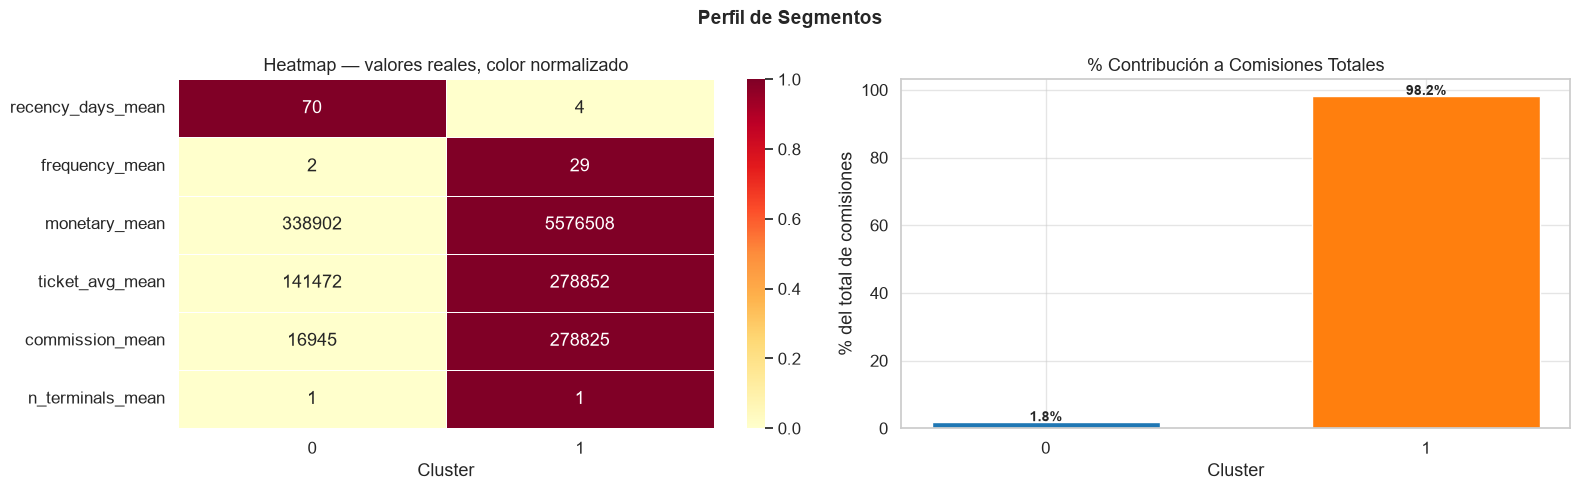

📊 Guardado: ..\data\processed\plots\cluster_profiles_k_means_var3.png

═══════════════════════════════════════════════════════════════════
PERFIL DE SEGMENTOS
═══════════════════════════════════════════════════════════════════


,n_comercios,recency_days_mean,recency_days_median,frequency_mean,frequency_median,monetary_mean,monetary_median,ticket_avg_mean,commission_sum,commission_mean,n_terminals_mean,active_months_mean,pct_comercios,pct_commission,gap_to_meta_cop,churn_signal_pct,api_adoption_proxy
cluster,,,,,,,,,,,,,,,,,
0,684,70.19,61.0,2.38,1.0,338902.12,3000.0,141471.89,1.159045e+07,16945.11,1.01,1.24,22.7,1.8,5953793.0,89.2,0.90
1,2331,3.60,0.0,28.54,14.0,5576508.49,2629700.0,278851.51,6.499421e+08,278825.42,1.02,3.22,77.3,98.2,324812466.0,0.9,0.34



─── KPIs Globales ───────────────────────────────────────────────
  Comisiones totales actuales : COP $    661,532,517
  Meta +50%                   : COP $    992,298,775
  Gap a cerrar                : COP $    330,766,258

─── Señal de churn por cluster (recency_days > 60) ──────────────
  Cluster 0: 89.2% en riesgo
  Cluster 1: 0.9% en riesgo


In [15]:
profile_df = profile_segments(df_orig, labels)

print("\n═══════════════════════════════════════════════════════════════════")
print("PERFIL DE SEGMENTOS")
print("═══════════════════════════════════════════════════════════════════")
display(profile_df.set_index("cluster"))

# KPIs resumen
total_comm = df_orig["commission"].sum()
print(f"\n─── KPIs Globales ───────────────────────────────────────────────")
print(f"  Comisiones totales actuales : COP ${total_comm:>15,.0f}")
print(f"  Meta +50%                   : COP ${total_comm * 1.5:>15,.0f}")
print(f"  Gap a cerrar                : COP ${total_comm * 0.5:>15,.0f}")
print()
print("─── Señal de churn por cluster (recency_days > 60) ──────────────")
for _, row in profile_df.iterrows():
    print(f"  Cluster {int(row['cluster'])}: {row['churn_signal_pct']:.1f}% en riesgo")

## 10. Exportación de Artefactos

Exportamos todos los artefactos del proceso para trazabilidad, reproducibilidad y  
consumo downstream (BI, modelos de TCRM, reportes):

| Artefacto | Descripción |
|-----------|-------------|
| `comercios_final.csv` | Dataset completo con cluster, features originales y transformadas |
| `perfiles_segmentos.csv` | Perfil estadístico + KPIs por cluster |
| `metadata_segmentation.json` | Trazabilidad: parámetros, transform_info, date_cutoff, métricas |
| `plots/` | Todos los gráficos generados en PNG |

In [16]:
# ── comercios_final.csv ───────────────────────────────────────────────────
df_final = df_orig.copy()
df_final["cluster"] = labels.astype(int)

# Añadir features transformadas con sufijo _log para trazabilidad
for col in transform_info["log_transformed"]:
    df_final[f"{col}_log"] = np.log1p(df_final[col])

final_path = DATA_DIR / f"comercios_final{SUFFIX}.csv"
df_final.to_csv(final_path, index=False)
print(f"💾 {final_path.name:40s} → {len(df_final):,} filas  {df_final.shape[1]} cols")

# ── metadata_segmentation.json ────────────────────────────────────────────
metadata = {
    "generated_at"  : datetime.now().isoformat(),
    "date_cutoff"   : "2021-05-01",
    "source_file"   : "comercios_segmented_prep.csv",
    "n_comercios"   : int(len(df_final)),
    "K_selected"    : int(K_SELECTED),
    "random_state"  : RANDOM_STATE,
    "scale_method"  : SCALE_METHOD,
    "inertia"       : round(float(km_model.inertia_), 4),
    "silhouette"    : round(float(sil_final), 4),
    "transform_info": transform_info,
    "cluster_sizes" : {
        int(k): int(v)
        for k, v in zip(*np.unique(labels, return_counts=True))
    },
    "kpis_globales" : {
        "commission_total_cop"  : round(float(df_orig["commission"].sum()), 2),
        "commission_meta_50pct" : round(float(df_orig["commission"].sum() * 1.5), 2),
        "gap_cop"               : round(float(df_orig["commission"].sum() * 0.5), 2),
    },
}

meta_path = DATA_DIR / f"metadata_segmentation{SUFFIX}.json"
with open(meta_path, "w", encoding="utf-8") as fh:
    json.dump(metadata, fh, indent=2, ensure_ascii=False)
print(f"💾 {meta_path.name:40s} → trazabilidad guardada")

# ── Inventario de plots ───────────────────────────────────────────────────
print(f"\n📁 Plots en {PLOTS_DIR.resolve()}:")
for p in sorted(PLOTS_DIR.glob("*.png")):
    size_kb = p.stat().st_size / 1024
    print(f"   {p.name:<40s} {size_kb:>6.1f} KB")

💾 comercios_final_k_means_var3.csv         → 3,015 filas  23 cols
💾 metadata_segmentation_k_means_var3.json  → trazabilidad guardada

📁 Plots en C:\Users\johan\OneDrive\Documentos\prueba-tecnica-pragma\data\processed\plots:
   cluster_profiles.png                       68.6 KB
   cluster_profiles_k_means_var3.png          68.8 KB
   cluster_profiles_k_means_var6.png          68.6 KB
   correlation_matrix.png                     85.7 KB
   correlation_matrix_k_means_var3.png        85.7 KB
   correlation_matrix_k_means_var6.png        85.7 KB
   distributions_raw.png                     102.6 KB
   distributions_raw_k_means_var3.png        102.6 KB
   distributions_raw_k_means_var6.png        102.6 KB
   elbow_silhouette.png                       62.5 KB
   elbow_silhouette_k_means_var3.png          61.2 KB
   elbow_silhouette_k_means_var6.png          62.5 KB
   monetary_log_comparison.png                44.0 KB
   monetary_log_comparison_k_means_var3.png   44.0 KB
   monetary_log_comp

## 11. Conclusiones y Recomendaciones Accionables

> ⚠️ **Completa esta sección** con los valores reales de `perfiles_segmentos.csv`.  
> La tabla a continuación es un template interpretativo — los nombres de clusters  
> deben asignarse revisando el perfil de cada grupo.

---

### Interpretación de Segmentos (template)

| Cluster | Perfil típico | Etiqueta de negocio | Palanca estratégica |
|---------|---------------|---------------------|---------------------|
| **0** | Recency baja · Frequency alta · Monetary alta | 🏆 **Champions** | Programa de referidos, beneficios premium, ampliar n_terminals |
| **1** | Recency media · Frequency media · Monetary media | 🚀 **En Crecimiento** | Upsell de features (QR, cuotas), incentivos por volumen |
| **2** | Recency alta · Frequency baja · Monetary baja | ⚠️ **En Riesgo** | Re-engagement: visitas comerciales, diagnóstico de fricciones |
| **3** | Recency baja · Frequency alta · Monetary baja | 🔄 **Frecuentes de Bajo Ticket** | Incrementar AOV: financiamiento, bundles, campañas de temporada |

---

### Estrategia para +50 % en Comisiones (meta Pragma)

La comisión se genera como `commission = monetary × 5%`. Para aumentar comisiones:

1. **Champions** → Retención y expansión:
   - Activar terminales inactivas · Ofrecer POS adicionales
   - Meta: +10 % en `monetary` de este segmento = mayor impacto absoluto

2. **En Crecimiento** → Educación y upsell:
   - Campañas de adopción de pagos digitales (billetera, QR)
   - Meta: convertir al menos 30 % en Champions en 6 meses

3. **En Riesgo** → Recuperación urgente:
   - Contacto proactivo si `recency_days > 60`
   - Meta: reducir churn al < 10 % del segmento

4. **Frecuentes de Bajo Ticket** → Incremento de `ticket_avg`:
   - Crédito en punto de venta · Campañas de agrupación de artículos
   - Meta: +25 % en `ticket_avg` → impacto directo en `monetary`

---

### KPIs de Monitoreo Mensual (por segmento)

| KPI | Fórmula | Frecuencia |
|-----|---------|-----------|
| Ticket promedio | `monetary / frequency` | Mensual |
| Tasa de churn | `% comercios con recency_days > 60` | Mensual |
| Adopción API | `n_terminals_activas / n_terminals_instaladas` | Mensual |
| Comisiones per cápita | `commission / n_comercios` | Mensual |
| Conversión Champions | `% que pasan a Cluster Champion` | Trimestral |

## 12. (Opcional) Análisis de Sensibilidad — Log-Transform ON vs. OFF

Validamos que la decisión de aplicar `log1p` mejora la calidad del clustering  
comparando el Silhouette Score para cada K con ambas configuraciones.

Silhouette Score — Comparativa Log-Transform ON vs. OFF:


,K=2,K=3,K=4,K=5,K=6,K=7,K=8,K=9,K=10
configuracion,,,,,,,,,
log1p=ON,0.6261,0.3998,0.4175,0.4321,0.3969,0.4006,0.4006,0.4022,0.4080
log1p=OFF,0.7138,0.6117,0.5117,0.5282,0.5248,0.5011,0.5135,0.5026,0.4681


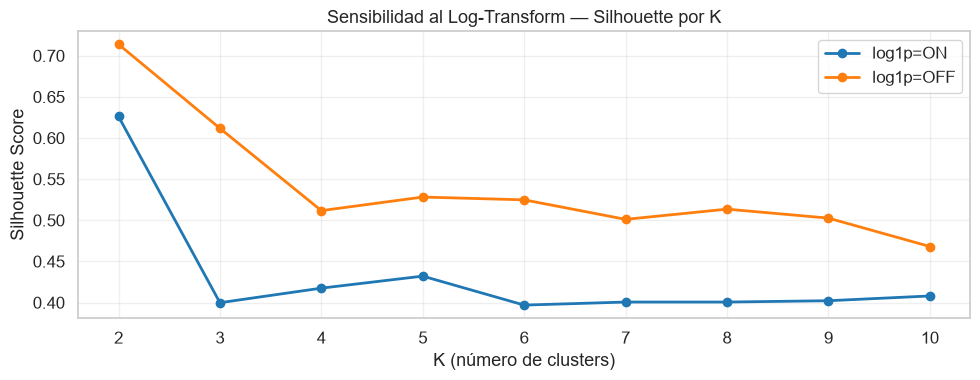


📊 Guardado: ..\data\processed\plots\sensitivity_analysis_k_means_var3.png


In [17]:
def scale_features(X: pd.DataFrame, method: str = "robust") -> tuple:
    """Escala features usando StandardScaler o RobustScaler.

    Args:
        X: DataFrame de features (ya transformadas, post-log1p si aplica).
        method: "standard" para StandardScaler, "robust" para RobustScaler.

    Returns:
        Tuple (X_scaled, scaler) donde:
            - X_scaled: np.ndarray con features escaladas.
            - scaler: objeto StandardScaler o RobustScaler ajustado.
    """
    if method == "standard":
        scaler = StandardScaler()
    else:
        scaler = RobustScaler()
    X_scaled = scaler.fit_transform(X)
    return X_scaled, scaler


sensitivity_rows = []

for use_log in [True, False]:
    label_str = "log1p=ON" if use_log else "log1p=OFF"
    X_s, _, _ = prepare_features(df_raw, log_transform=use_log,
                                  skew_threshold=SKEW_THRESHOLD)
    X_sc, _  = scale_features(X_s, method=SCALE_METHOD)
    row = {"configuracion": label_str}
    for k in K_RANGE:
        km  = KMeans(n_clusters=k, init="k-means++", n_init=10,
                     random_state=RANDOM_STATE)
        lbl = km.fit_predict(X_sc)
        row[f"K={k}"] = round(silhouette_score(X_sc, lbl), 4)
    sensitivity_rows.append(row)

sens_df = pd.DataFrame(sensitivity_rows).set_index("configuracion")
print("Silhouette Score — Comparativa Log-Transform ON vs. OFF:")
display(sens_df)

# Gráfico
fig, ax = plt.subplots(figsize=(10, 4))
for i, cfg in enumerate(sens_df.index):
    k_vals = [int(c.split("=")[1]) for c in sens_df.columns]
    ax.plot(k_vals, sens_df.loc[cfg].values, marker="o", linewidth=2,
            label=cfg, color=PALETTE[i])

ax.set_xlabel("K (número de clusters)")
ax.set_ylabel("Silhouette Score")
ax.set_title("Sensibilidad al Log-Transform — Silhouette por K")
ax.legend()
ax.set_xticks(list(K_RANGE))
ax.grid(True, alpha=0.3)
plt.tight_layout()
sens_path = PLOTS_DIR / f"sensitivity_analysis{SUFFIX}.png"
plt.savefig(sens_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"\n📊 Guardado: {sens_path}")

## 13. (Opcional) Visualización 2D con PCA

Proyectamos las features escaladas en los **dos primeros componentes principales**  
para una inspección visual de la separación entre clusters.  
Los centroides K-Means se muestran con marcador ✕.

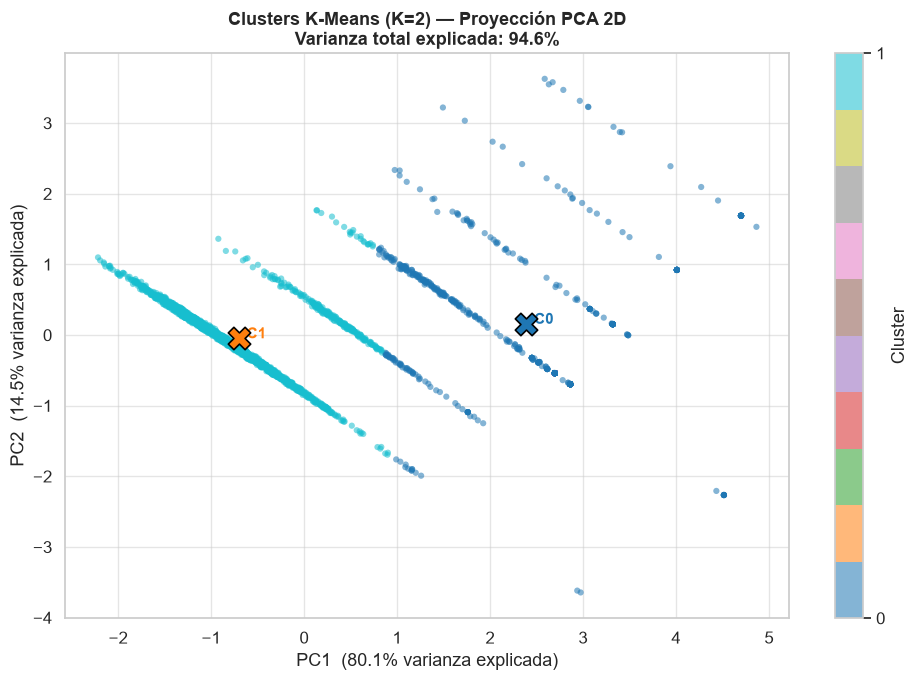

📊 Guardado: ..\data\processed\plots\pca_clusters_k_means_var3.png
Varianza PC1+PC2: 94.6%


In [18]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels, cmap="tab10", alpha=0.55, s=20, edgecolors="none",
)

# Centroides en espacio PCA
centroids_pca = pca.transform(km_model.cluster_centers_)
for i, (cx, cy) in enumerate(centroids_pca):
    ax.scatter(cx, cy, s=260, marker="X", zorder=5,
               color=PALETTE[i % 10], edgecolors="black", linewidths=1.2)
    ax.annotate(f"  C{i}", (cx, cy), fontsize=11,
                fontweight="bold", color=PALETTE[i % 10])

ax.set_xlabel(f"PC1  ({var_exp[0]*100:.1f}% varianza explicada)")
ax.set_ylabel(f"PC2  ({var_exp[1]*100:.1f}% varianza explicada)")
ax.set_title(
    f"Clusters K-Means (K={K_SELECTED}) — Proyección PCA 2D\n"
    f"Varianza total explicada: {sum(var_exp)*100:.1f}%",
    fontsize=13, fontweight="bold",
)
plt.colorbar(scatter, ax=ax, label="Cluster",
             ticks=range(K_SELECTED))
plt.tight_layout()
pca_path = PLOTS_DIR / f"pca_clusters{SUFFIX}.png"
plt.savefig(pca_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"📊 Guardado: {pca_path}")
print(f"Varianza PC1+PC2: {sum(var_exp)*100:.1f}%")

## 14. Visualización 3D del Espacio RFM

Un punto por **`id_comercio`** en el espacio de las tres variables núcleo del modelo —
**recencia × frecuencia × monto** — coloreado por el cluster asignado por K-Means.

**Decisiones de lectura:**

| Decisión | Motivo |
|----------|--------|
| Ejes `frequency` y `monetary` en escala `log1p` | Skew 6.3 y 4.3 → en escala lineal el 95 % de los comercios se apila contra el origen |
| Ticks rotulados en **escala original** (`$100K`, `$10M`, `300 trx`) | El eje sigue siendo interpretable por negocio pese a la transformación |
| `recency_days` en escala lineal | Skew 1.8 y rango acotado (0–151 días); es directamente legible |
| ✕ = centroide **observado** (media en escala original) | Más interpretable que `cluster_centers_`, que vive en el espacio escalado |
| Los comercios de mayor monto se resaltan con anillo y se listan | Son los que concentran el gap de comisiones; identificarlos por `id_comercio` los hace accionables |

> Las **franjas verticales** visibles en el eje de recencia no son un artefacto del gráfico:
> `recency_days` se concentra en múltiplos de ~30 días porque muchos comercios sólo
> transaccionan una vez al mes.

> ⚠️ Un scatter 3D estático sufre **ambigüedad de profundidad**: la posición aparente de un
> punto depende del ángulo de cámara. Para conclusiones cuantitativas usa el perfil de la
> sección 9; este gráfico es para inspección de **forma y separación** de los segmentos.


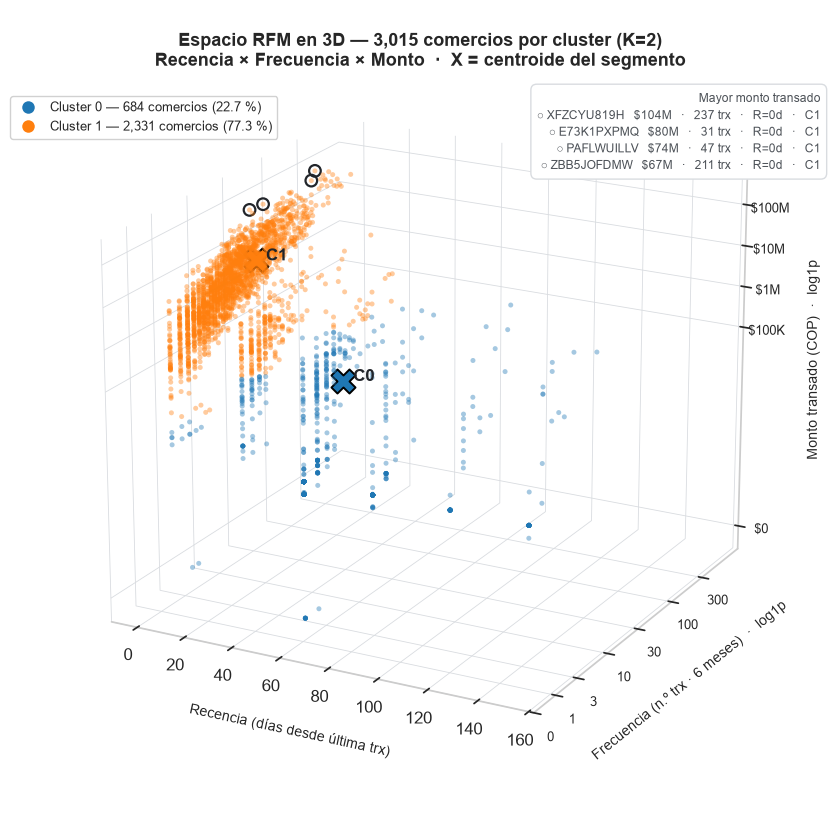

📊 Guardado: ..\data\processed\plots\rfm_3d_clusters_k_means_var3.png

Centroide observado por segmento (escala original):


AttributeError: 'Figure' object has no attribute 'set_index'

In [19]:
# Gráfico 3D de las variables monetary, recency y frecuencia por id_comercio
def _fmt_cop(v: float) -> str:
    """Formatea un monto en COP con sufijo legible (K / M / MM)."""
    for div, suf in ((1e9, "MM"), (1e6, "M"), (1e3, "K")):
        if v >= div:
            return f"${v / div:,.0f}{suf}"
    return f"${v:,.0f}"


def plot_rfm_3d(
    df_orig: pd.DataFrame,
    labels: np.ndarray,
    log_axes: tuple = ("frequency", "monetary"),
    top_n_labels: int = 4,
    elev: int = 20,
    azim: int = -62,
    save_path: Optional[Path] = None,
) -> pd.DataFrame:
    """Grafica el espacio RFM en 3D: recencia × frecuencia × monto, un punto por comercio.

    Cada punto es un `id_comercio` coloreado por su cluster K-Means. Los ejes
    `frequency` y `monetary` se dibujan en escala `log1p` (skew 6.3 y 4.3) pero se
    rotulan con valores en escala original para que sigan siendo interpretables por
    negocio. El marcador ✕ señala el centroide observado de cada segmento y los
    `top_n_labels` comercios de mayor monto se resaltan con anillo negro.

    Args:
        df_orig: DataFrame con variables en escala natural (pre-transformación),
            incluyendo `id_comercio`, `recency_days`, `frequency` y `monetary`.
        labels: Array 1D con la asignación de cluster por comercio (base-0).
        log_axes: Variables a dibujar en escala log1p.
        top_n_labels: Cuántos comercios de mayor `monetary` resaltar e identificar.
        elev: Elevación de la cámara en grados.
        azim: Azimut de la cámara en grados.
        save_path: Ruta del .png a guardar. Si None, no guarda.

    Returns:
        DataFrame con el centroide observado (media en escala original) por cluster.
    """
    axes_spec = [
        ("recency_days", "Recencia (días desde última trx)",
         [0, 20, 40, 60, 80, 100, 120, 140]),
        ("frequency", "Frecuencia (n.º trx · 6 meses)",
         [0, 1, 3, 10, 30, 100, 300, 1000]),
        ("monetary", "Monto transado (COP)",
         [0, 1e5, 1e6, 1e7, 1e8, 1e9]),
    ]

    df_p = df_orig.copy()
    df_p["cluster"] = labels.astype(int)
    K = int(df_p["cluster"].max()) + 1

    def coord(col, values):
        """Convierte valores a la escala de dibujo del eje."""
        return np.log1p(values) if col in log_axes else values

    xyz = {col: coord(col, df_p[col]) for col, _, _ in axes_spec}

    fig = plt.figure(figsize=(12, 9))
    ax = fig.add_subplot(projection="3d")

    # Clusters grandes primero → los pequeños quedan visibles encima
    for cl in df_p["cluster"].value_counts().index.tolist():
        m = df_p["cluster"] == cl
        ax.scatter(
            xyz["recency_days"][m], xyz["frequency"][m], xyz["monetary"][m],
            color=PALETTE[cl % 10], s=13, alpha=0.40,
            edgecolors="none", depthshade=False,
        )

    # ── Centroides observados (media en escala original) ──────────────────
    centroids = (
        df_p.groupby("cluster")[["recency_days", "frequency", "monetary"]]
        .mean()
        .reset_index()
    )
    for _, row in centroids.iterrows():
        cl = int(row["cluster"])
        cx, cy, cz = (coord(c, row[c]) for c in
                      ("recency_days", "frequency", "monetary"))
        # Halo blanco para que el centroide no se pierda en la nube de puntos
        ax.scatter(cx, cy, cz, marker="X", s=430, depthshade=False,
                   color="white", edgecolors="white", linewidths=2.0)
        ax.scatter(cx, cy, cz, marker="X", s=300, depthshade=False,
                   color=PALETTE[cl % 10], edgecolors="black", linewidths=1.4)
        ax.text(cx, cy, cz, f"  C{cl}", fontsize=12, fontweight="bold",
                color="#22252a", zorder=10)

    # ── Comercios de mayor monto: anillo + listado (evita solapar rótulos) ─
    top = df_p.nlargest(top_n_labels, "monetary") if top_n_labels else df_p.iloc[:0]
    if len(top):
        ax.scatter(
            coord("recency_days", top["recency_days"]),
            coord("frequency", top["frequency"]),
            coord("monetary", top["monetary"]),
            s=70, facecolors="none", edgecolors="#22252a", linewidths=1.6,
            depthshade=False,
        )
        listado = "\n".join(
            f"○ {r.id_comercio}   {_fmt_cop(r.monetary)}   ·   {r.frequency:,.0f} trx"
            f"   ·   R={r.recency_days:.0f}d   ·   C{int(r.cluster)}"
            for r in top.itertuples()
        )
        ax.text2D(
            1.0, 0.90, f"Mayor monto transado\n{listado}",
            transform=ax.transAxes, fontsize=8.5, color="#4c5157",
            va="top", ha="right", linespacing=1.5,
            bbox=dict(boxstyle="round,pad=0.5", facecolor="white",
                      edgecolor="#d9dce0"),
        )

    # ── Ejes: ticks en escala original, etiquetas de negocio ──────────────
    ax.zaxis.set_rotate_label(False)
    setters = (
        (ax.set_xlabel, ax.set_xticks, ax.set_xticklabels, {}),
        (ax.set_ylabel, ax.set_yticks, ax.set_yticklabels, {}),
        (ax.set_zlabel, ax.set_zticks, ax.set_zticklabels, {"rotation": 90}),
    )
    for (col, label, cands), (set_label, set_ticks, set_labels, kw) in zip(
        axes_spec, setters
    ):
        suffix = "  ·  log1p" if col in log_axes else ""
        set_label(f"{label}{suffix}", fontsize=10, labelpad=14, **kw)
        if col in log_axes:
            vals = [c for c in cands if c <= df_p[col].max() * 1.05]
            set_ticks(np.log1p(vals))
            set_labels(
                [_fmt_cop(v) if col == "monetary" else f"{v:,.0f}" for v in vals],
                fontsize=9,
            )

    # ── Estética recesiva de paneles y rejilla ────────────────────────────
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((1.0, 1.0, 1.0, 0.0))
        axis._axinfo["grid"].update(color="#d9dce0", linewidth=0.6)

    ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect((1, 1, 0.85), zoom=0.94)
    ax.set_title(
        f"Espacio RFM en 3D — {len(df_p):,} comercios por cluster (K={K})\n"
        "Recencia × Frecuencia × Monto  ·  X = centroide del segmento",
        fontsize=13, fontweight="bold", y=1.0,
    )

    # ── Leyenda categórica: la identidad nunca depende sólo del color ─────
    sizes = df_p["cluster"].value_counts().sort_index()
    handles = [
        Line2D([0], [0], marker="o", linestyle="none", markersize=9,
               markerfacecolor=PALETTE[cl % 10], markeredgecolor="none",
               label=f"Cluster {cl} — {n:,} comercios ({n / len(df_p) * 100:.1f} %)")
        for cl, n in sizes.items()
    ]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(-0.02, 0.90),
              frameon=True, framealpha=0.9, fontsize=9)

    fig.subplots_adjust(left=0.03, right=0.92, top=0.94, bottom=0.05)
    if save_path is not None:
        plt.savefig(save_path, dpi=130, bbox_inches="tight")
    return fig


# ── Ejecutar ──────────────────────────────────────────────────────────────
rfm3d_path = PLOTS_DIR / f"rfm_3d_clusters{SUFFIX}.png"
centroids_3d = plot_rfm_3d(df_orig, labels, save_path=rfm3d_path)
display(plt.gcf())
plt.close()

print(f"📊 Guardado: {rfm3d_path}\n")
print("Centroide observado por segmento (escala original):")
display(centroids_3d.set_index("cluster").round(1))
